# Naive Bayes and Decision Trees

In [1]:
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
from IPython.display import display

from src import text_clusters as tc
from src import text_nb as nb
from src.clean_ats import classify_role_family
from src.plotstyle import apply_style, save

apply_style()
pd.set_option("display.max_colwidth", 200)
report = []  # lines for results/nb_report.txt

## 1. Naive Bayes

### Data preparation

In [2]:
df, load_log = nb.load_subset()
print("\n".join(load_log))
y = df.role_family
counts = y.value_counts().reindex(nb.CLASSES)
print(f"\nthree-class subset: {len(df):,} rows")
print(counts.to_string())
assert counts.tolist() == [163, 275, 721]
report += ["DATA", *[f"  {line}" for line in load_log],
           f"  three-class subset: {len(df)} rows",
           *[f"    {c}: {n}" for c, n in counts.items()]]

rows before dedup: 4294
near-duplicate groups: 357 (933 rows flagged is_near_dup)
group size distribution (copies per group: number of groups):
  2: 242
  3: 66
  4: 24
  5: 15
  6: 3
  7: 2
  8: 1
  9: 2
  10: 1
  12: 1
removed as extra copies: 576
rows after dedup: 3718
is_junk: column not present in ats_final.csv, nothing to drop

three-class subset: 1,159 rows
role_family
forward_deployed    163
solutions           275
software_eng        721


In [3]:
TEXTS = nb.build_variants(df)
mask = nb.masking_summary(TEXTS["stripped"], TEXTS["masked"])
print("role phrases masked (case-insensitive, whole phrase, optional plural):", nb.ROLE_PHRASES)
print(f"rows changed by masking: {mask['rows_changed']} of {mask['rows']}")
print(f"median characters removed: {mask['median_chars_removed_changed_rows']:.0f} on changed rows "
      f"({mask['median_pct_removed_changed_rows']:.2f}% of the text), "
      f"{mask['median_chars_removed_all_rows']:.0f} over all rows")
for v, text in TEXTS.items():
    print(f"median length, {v}: {text.str.len().median():,.0f} characters")

# postings containing each phrase in the stripped text (exact whole tokens, before masking)
hits = nb.phrase_hits(TEXTS["stripped"], df)
display(hits)

# how much of the labelling rule survives in each variant: classify_role_family()
# run on the description text instead of the title
rule = {v: (text.apply(classify_role_family) == y) for v, text in TEXTS.items()}
print("\ntitle rule applied to the description reproduces the label:")
print(pd.DataFrame({v: r.groupby(y).sum() for v, r in rule.items()}).reindex(nb.CLASSES)
      .assign(n=counts).to_string())
report += ["", "ROLE-PHRASE MASKING",
           f"  phrases: {nb.ROLE_PHRASES} (plus the posting's own title)",
           f"  rows changed: {mask['rows_changed']} of {mask['rows']}",
           f"  median characters removed: {mask['median_chars_removed_changed_rows']:.0f} on changed rows "
           f"({mask['median_pct_removed_changed_rows']:.2f}%), {mask['median_chars_removed_all_rows']:.0f} over all rows",
           "  title rule on description reproduces label: "
           + ", ".join(f"{v} {int(r.sum())}/{len(r)}" for v, r in rule.items()),
           "  postings containing each phrase (stripped text, exact whole tokens, before masking):",
           *[f"    {line}" for line in hits.to_string().splitlines()]]

role phrases masked (case-insensitive, whole phrase, optional plural): ['forward deployed', 'forward-deployed', 'fde', 'solutions architect', 'solutions engineer', 'solution architect', 'field engineer', 'field engineering', 'software engineer', 'software engineering', 'deployment strategist', 'deployment engineer', 'fdse', 'fdses', 'forward deployed software engineer', 'forward deployed software engineers', 'sa', 'sas', 'dsa', 'dsas', 'delivery solutions architect', 'delivery solutions architects', 'ssa', 'ssas']
rows changed by masking: 865 of 1159
median characters removed: 38 on changed rows (1.14% of the text), 21 over all rows
median length, raw: 5,953 characters
median length, stripped: 3,155 characters
median length, masked: 3,104 characters


,postings,forward_deployed,solutions,software_eng,companies
phrase,,,,,
forward deployed,188,128,29,31,"Databricks 60, Palantir 55, Scale AI 24, OpenAI 20, Cohere 10, Anthropic 5, Vercel 4, Sierra 3, Ramp 2, Amplitude 2, Perplexity 1, Figma 1, Asana 1"
forward-deployed,188,128,29,31,"Databricks 60, Palantir 55, Scale AI 24, OpenAI 20, Cohere 10, Anthropic 5, Vercel 4, Sierra 3, Ramp 2, Amplitude 2, Perplexity 1, Figma 1, Asana 1"
fde,82,64,16,2,"Databricks 56, OpenAI 6, Palantir 5, Cohere 5, Anthropic 3, Scale AI 2, Vercel 2, Perplexity 1, Ramp 1, Amplitude 1"
solutions architect,123,13,110,0,"Databricks 108, Cohere 4, OpenAI 3, Vercel 3, Airtable 2, Perplexity 1, Asana 1, Webflow 1"
solutions engineer,29,3,26,0,"Databricks 17, Scale AI 2, Cohere 2, Asana 2, Anthropic 1, OpenAI 1, Perplexity 1, Webflow 1, Linear 1, Vercel 1"
solution architect,15,0,15,0,"Databricks 14, Vercel 1"
field engineer,2,0,2,0,Vercel 2
field engineering,99,12,87,0,"Databricks 93, Vercel 5, Anthropic 1"
software engineer,320,14,7,299,"Databricks 82, OpenAI 66, Palantir 32, Anthropic 30, Scale AI 24, Harvey 23, Discord 14, Vercel 10, Asana 9, Amplitude 7, Webflow 6, Sierra 4, Cohere 4, Ramp 4, Perplexity 3, Stripe 1, Airtable 1"



title rule applied to the description reproduces the label:
                  raw  stripped  masked    n
role_family                                 
forward_deployed  144       130       1  163
solutions         235       232     183  275
software_eng      517       516     496  721


### Train / test split

In [4]:
# one stratified split of the row positions, reused by every variant and model
train, test = nb.split_rows(y)
split_counts = pd.DataFrame({"train": y.iloc[train].value_counts(),
                             "test": y.iloc[test].value_counts()}).reindex(nb.CLASSES)
split_counts.loc["total"] = split_counts.sum()
print(f"test_size = {nb.TEST_SIZE}, random_state = {nb.SPLIT_SEED}, stratified on role_family")
print(split_counts.to_string())
overlap = set(df.jobId.iloc[train]) & set(df.jobId.iloc[test])
print(f"jobId overlap between train and test: {len(overlap)}")
assert not overlap

LIMITATION = ("The Module 2 boilerplate sentences were found across all 3,718 postings, "
              "including the rows now in the test set, so the stripped and masked variants "
              "use a list that saw the test text. Only which sentences to drop was learned "
              "this way; the vectoriser and the models are fitted on training rows only.")
print("\nLIMITATION:", LIMITATION)
report += ["", "SPLIT", f"  test_size = {nb.TEST_SIZE}, random_state = {nb.SPLIT_SEED}, stratified",
           *[f"  {line}" for line in split_counts.to_string().splitlines()],
           f"  jobId overlap: {len(overlap)}", f"  LIMITATION: {LIMITATION}"]

test_size = 0.2, random_state = 42, stratified on role_family
                  train  test
role_family                  
forward_deployed    130    33
solutions           220    55
software_eng        577   144
total               927   232
jobId overlap between train and test: 0

LIMITATION: The Module 2 boilerplate sentences were found across all 3,718 postings, including the rows now in the test set, so the stripped and masked variants use a list that saw the test text. Only which sentences to drop was learned this way; the vectoriser and the models are fitted on training rows only.


In [5]:
# vectorisers are fitted on the training rows only and applied to the test rows
# every token must contain a letter, so pure numbers such as pay-band figures are dropped
NUMBER_TOKENS = ["182", "208", "247", "250", "301"]
report += ["", "FEATURES (fitted on training rows only)", f"  parameters: {nb.VECTOR_PARAMS}"]
print("parameters:", nb.VECTOR_PARAMS)
for v, text in TEXTS.items():
    for binary, kind in [(False, "TF-IDF"), (True, "binary counts")]:
        X_train, X_test, vec = nb.vectorize(text, train, test, binary)
        numbers = [t for t in vec.vocabulary_ if not any(ch.isalpha() for ch in t)]
        line = (f"{v:8s} {kind:13s}: train {X_train.shape[0]} x {X_train.shape[1]:,}, "
                f"test {X_test.shape[0]} x {X_test.shape[1]:,}, vocabulary {len(vec.vocabulary_):,}; "
                f"letterless tokens {len(numbers)}; "
                f"{', '.join(NUMBER_TOKENS)} in vocabulary: {[t for t in NUMBER_TOKENS if t in vec.vocabulary_]}")
        print(line)
        report.append(f"  {line}")

parameters: {'min_df': 5, 'max_df': 0.8, 'stop_words': 'english', 'token_pattern': '(?u)\\b(?=\\w*[^\\W\\d_])\\w\\w+\\b'}


raw      TF-IDF       : train 927 x 4,212, test 232 x 4,212, vocabulary 4,212; letterless tokens 0; 182, 208, 247, 250, 301 in vocabulary: []


raw      binary counts: train 927 x 4,212, test 232 x 4,212, vocabulary 4,212; letterless tokens 0; 182, 208, 247, 250, 301 in vocabulary: []
stripped TF-IDF       : train 927 x 3,641, test 232 x 3,641, vocabulary 3,641; letterless tokens 0; 182, 208, 247, 250, 301 in vocabulary: []


stripped binary counts: train 927 x 3,641, test 232 x 3,641, vocabulary 3,641; letterless tokens 0; 182, 208, 247, 250, 301 in vocabulary: []
masked   TF-IDF       : train 927 x 3,631, test 232 x 3,631, vocabulary 3,631; letterless tokens 0; 182, 208, 247, 250, 301 in vocabulary: []


masked   binary counts: train 927 x 3,631, test 232 x 3,631, vocabulary 3,631; letterless tokens 0; 182, 208, 247, 250, 301 in vocabulary: []


### Models

In [6]:
# alpha is chosen by stratified k-fold CV on the training rows only (vectoriser refitted
# inside every fold); the test set is used once, at the selected alpha
baseline = nb.majority_baseline(y, train, test)
print(f"majority-class baseline: always predict {baseline[0]} -> test accuracy {baseline[1]:.4f}")
results = {v: nb.run_variant(TEXTS[v], y, train, test) for v in nb.VARIANTS}
cv_table = pd.concat({(v, m): r["cv"] for v in results for m, r in results[v].items()},
                     names=["variant", "model"])
display(cv_table.round(4).unstack("alpha"))

majority-class baseline: always predict software_eng -> test accuracy 0.6207


cv_mean                                   cv_sd  \
alpha                     0.01    0.05    0.10    0.50    1.00    0.01   
variant  model                                                           
masked   BernoulliNB    0.9267  0.9310  0.9310  0.9353  0.9321  0.0316   
         MultinomialNB  0.9278  0.9321  0.9332  0.9148  0.8857  0.0336   
raw      BernoulliNB    0.7713  0.7508  0.7379  0.7185  0.7088  0.0274   
         MultinomialNB  0.8587  0.8533  0.8522  0.8403  0.8500  0.0427   
stripped BernoulliNB    0.9267  0.9321  0.9342  0.9386  0.9332  0.0316   
         MultinomialNB  0.9288  0.9407  0.9418  0.9213  0.8921  0.0318   

                                                        
alpha                     0.05    0.10    0.50    1.00  
variant  model                                          
masked   BernoulliNB    0.0329  0.0349  0.0345  0.0389  
         MultinomialNB  0.0344  0.0327  0.0307  0.0284  
raw      BernoulliNB    0.0371  0.0395  0.0288  0.0307  
         MultinomialNB  0.0460  0.0458  0.0432  0.0322  
stripped BernoulliNB    0.0340  0.0309  0.0320  0.0396  
         MultinomialNB  0.0272  0.0289  0.0316  0.0287

In [7]:
summary = lambda key: pd.DataFrame({v: {m: r[key] for m, r in results[v].items()} for v in nb.VARIANTS}).T
selected_alpha = summary("alpha")
accuracy = summary("accuracy")
default_accuracy = pd.DataFrame({v: {m: r["default"]["accuracy"] for m, r in results[v].items()}
                                 for v in nb.VARIANTS}).T
print("selected alpha (CV on training rows):"); display(selected_alpha)
print("HEADLINE test accuracy at the selected alpha:"); display(accuracy.round(4))
print("for comparison, test accuracy at alpha = 1.0 (sklearn default):"); display(default_accuracy.round(4))

selected alpha (CV on training rows):


,MultinomialNB,BernoulliNB
raw,0.01,0.01
stripped,0.10,0.50
masked,0.10,0.50


HEADLINE test accuracy at the selected alpha:


,MultinomialNB,BernoulliNB
raw,0.8362,0.7371
stripped,0.9181,0.9353
masked,0.9138,0.9353


for comparison, test accuracy at alpha = 1.0 (sklearn default):


,MultinomialNB,BernoulliNB
raw,0.8190,0.694
stripped,0.8664,0.931
masked,0.8621,0.931


In [8]:
# SENSITIVITY ONLY: test accuracy across alpha. Not used to choose alpha, because that
# would select on the test set.
test_sweep = pd.DataFrame({(v, m): r["test_sweep"] for v in results for m, r in results[v].items()}).T
test_sweep.index.names = ["variant", "model"]
test_sweep.columns = [f"alpha={a}" for a in test_sweep.columns]
test_sweep.round(4)

alpha=0.1  alpha=0.5  alpha=1.0
variant  model                                         
raw      MultinomialNB     0.8276     0.8103     0.8190
         BernoulliNB       0.7241     0.7026     0.6940
stripped MultinomialNB     0.9181     0.9052     0.8664
         BernoulliNB       0.9310     0.9353     0.9310
masked   MultinomialNB     0.9138     0.9009     0.8621
         BernoulliNB       0.9310     0.9353     0.9310

In [9]:
report += ["", "RESULTS (test set, n = %d)" % len(test)]
for v in nb.VARIANTS:
    for m, r in results[v].items():
        lines = nb.result_lines(v, m, r, baseline)
        print("\n".join(lines), end="\n\n")
        report += ["", *lines]

--- raw (raw descriptions) x MultinomialNB ---
features: train 927 x 4212, test 232 x 4212
5-fold stratified CV on the training rows (accuracy, mean +/- sd over folds):
  alpha 0.01 : 0.8587 +/- 0.0427
  alpha 0.05 : 0.8533 +/- 0.0460
  alpha 0.1  : 0.8522 +/- 0.0458
  alpha 0.5  : 0.8403 +/- 0.0432
  alpha 1.0  : 0.8500 +/- 0.0322
selected alpha: 0.01
TEST ACCURACY at selected alpha 0.01: 0.8362
majority-class baseline (software_eng): 0.6207
confusion matrix (rows = true, columns = predicted):
  predicted         forward_deployed  solutions  software_eng
  true                                                       
  forward_deployed                21          3             9
  solutions                        6         35            14
  software_eng                     6          0           138
classification report:
                    precision    recall  f1-score   support
  
  forward_deployed      0.636     0.636     0.636        33
         solutions      0.921     0.636     

### Raw descriptions

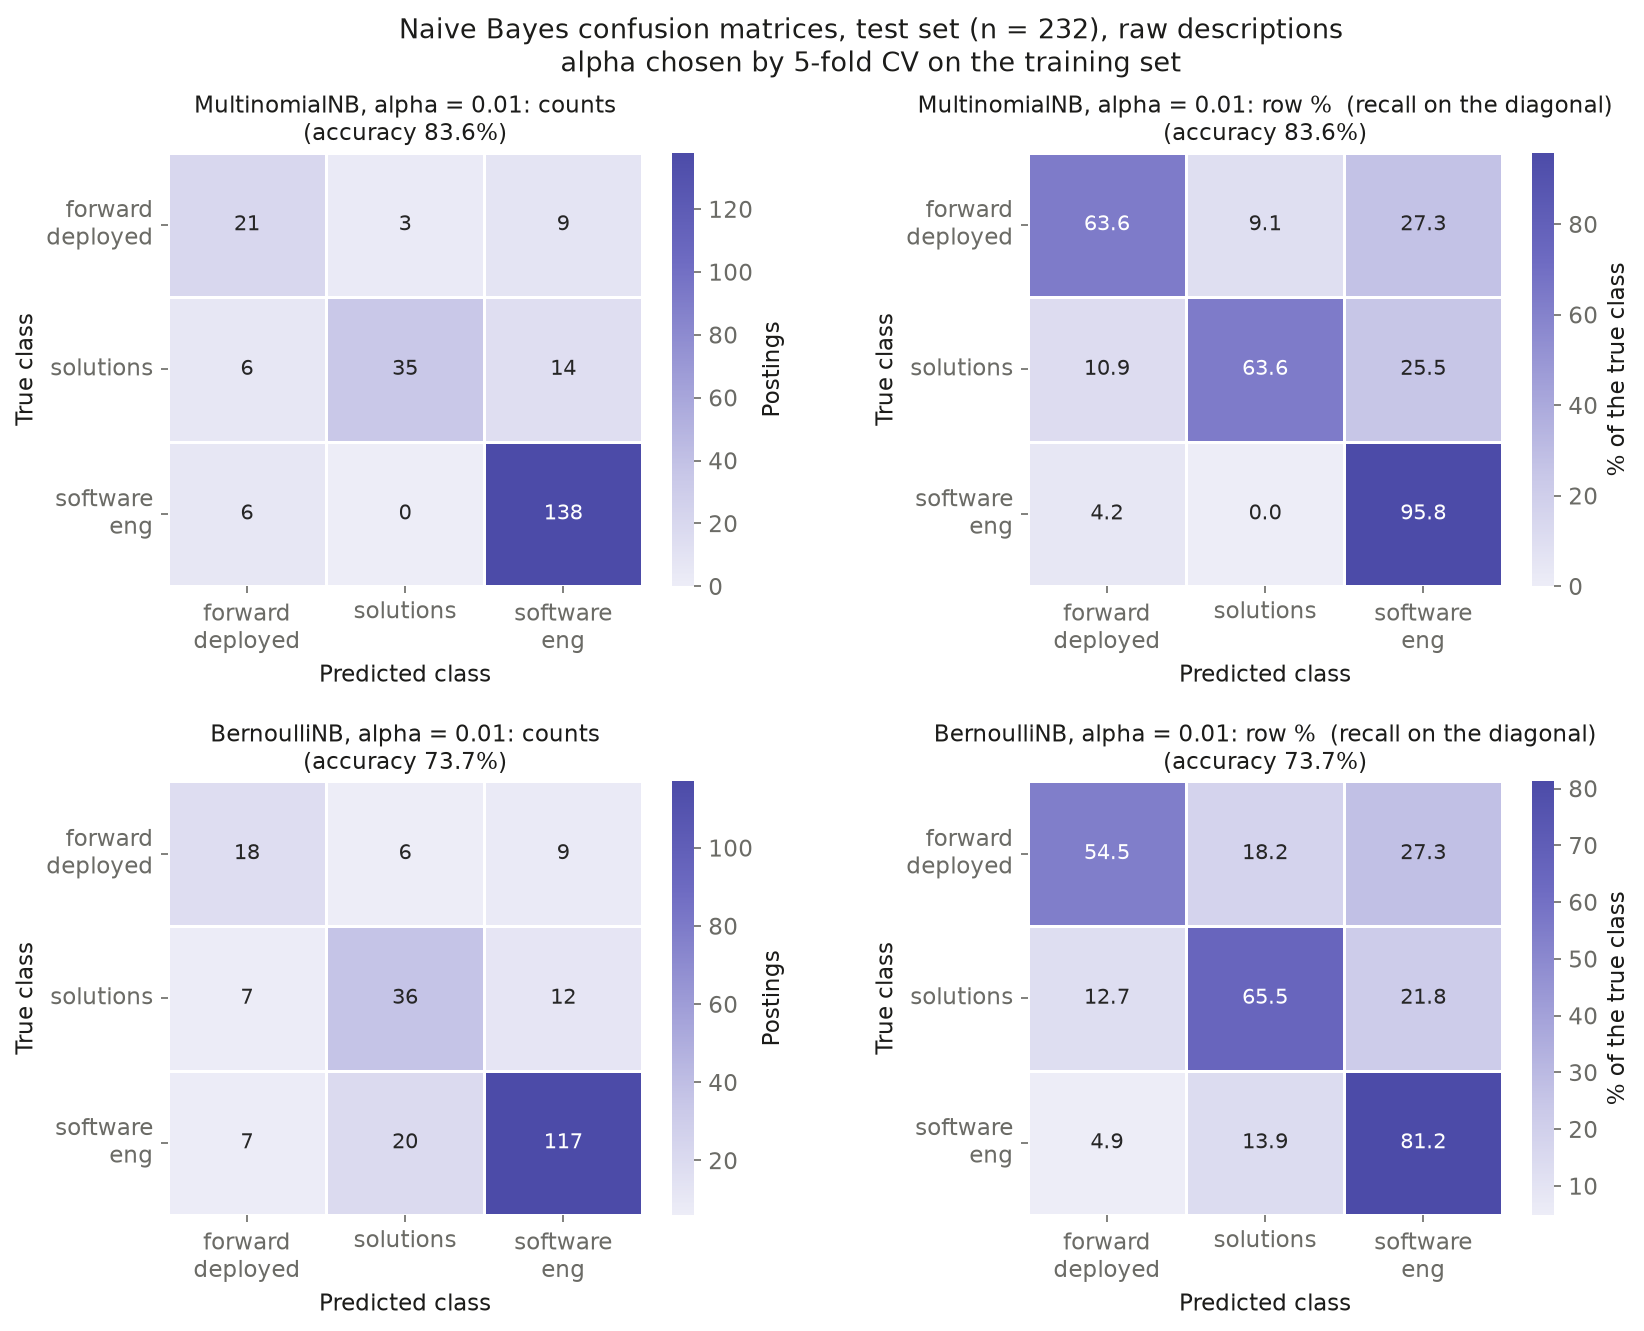

In [10]:
fig = nb.plot_confusion(results["raw"], nb.LABEL["raw"])
save(fig, "nb_confusion_raw")

## Insight
On the raw text, Multinomial NB gets 83.6% right and Bernoulli NB 73.7%. Both miss many forward_deployed and solutions postings and mostly call them software_eng.

### Company boilerplate removed

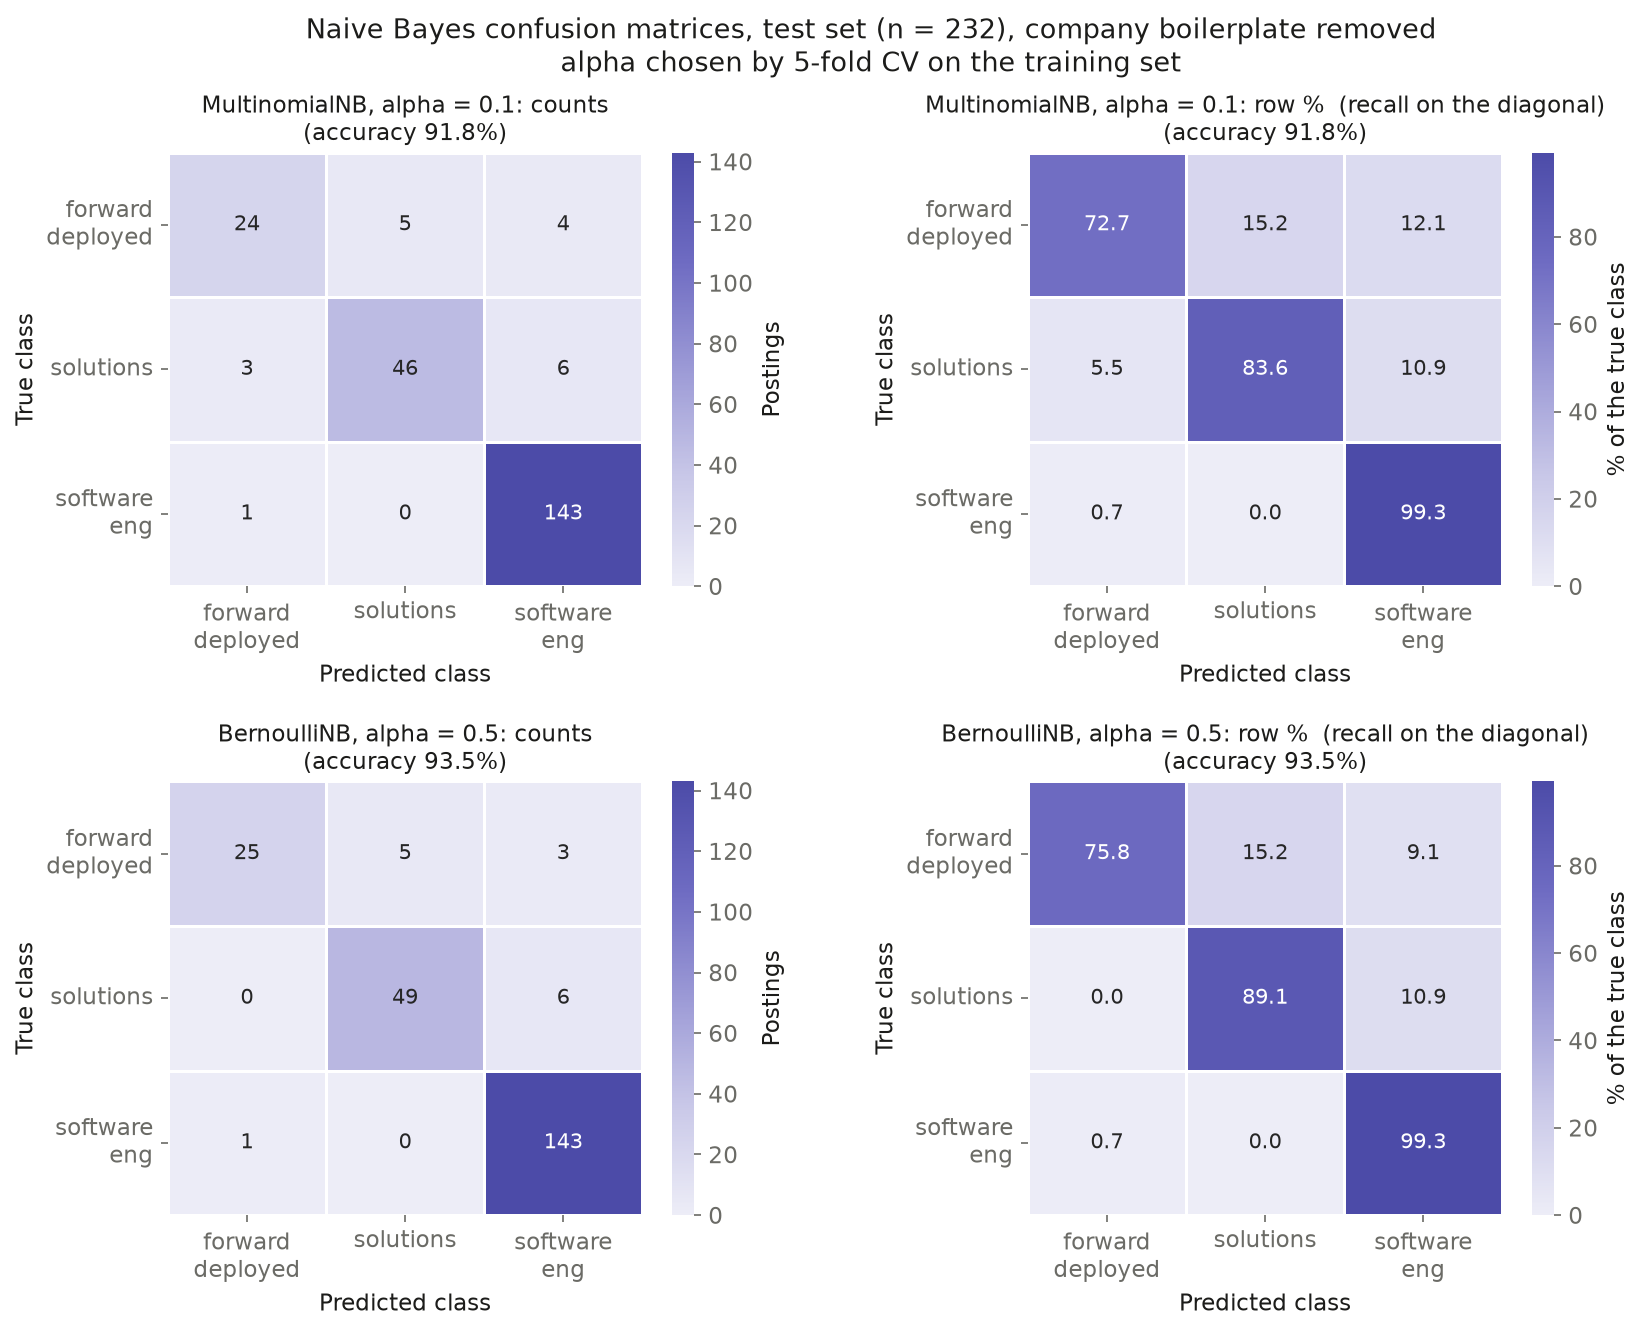

In [11]:
fig = nb.plot_confusion(results["stripped"], nb.LABEL["stripped"])
save(fig, "nb_confusion_stripped")

## Insight
Removing the text each company repeats in its postings lifts accuracy to 91.8% (Multinomial) and 93.5% (Bernoulli). Software_eng is almost always right, and forward_deployed is still the hardest.

### Boilerplate removed, role phrases masked

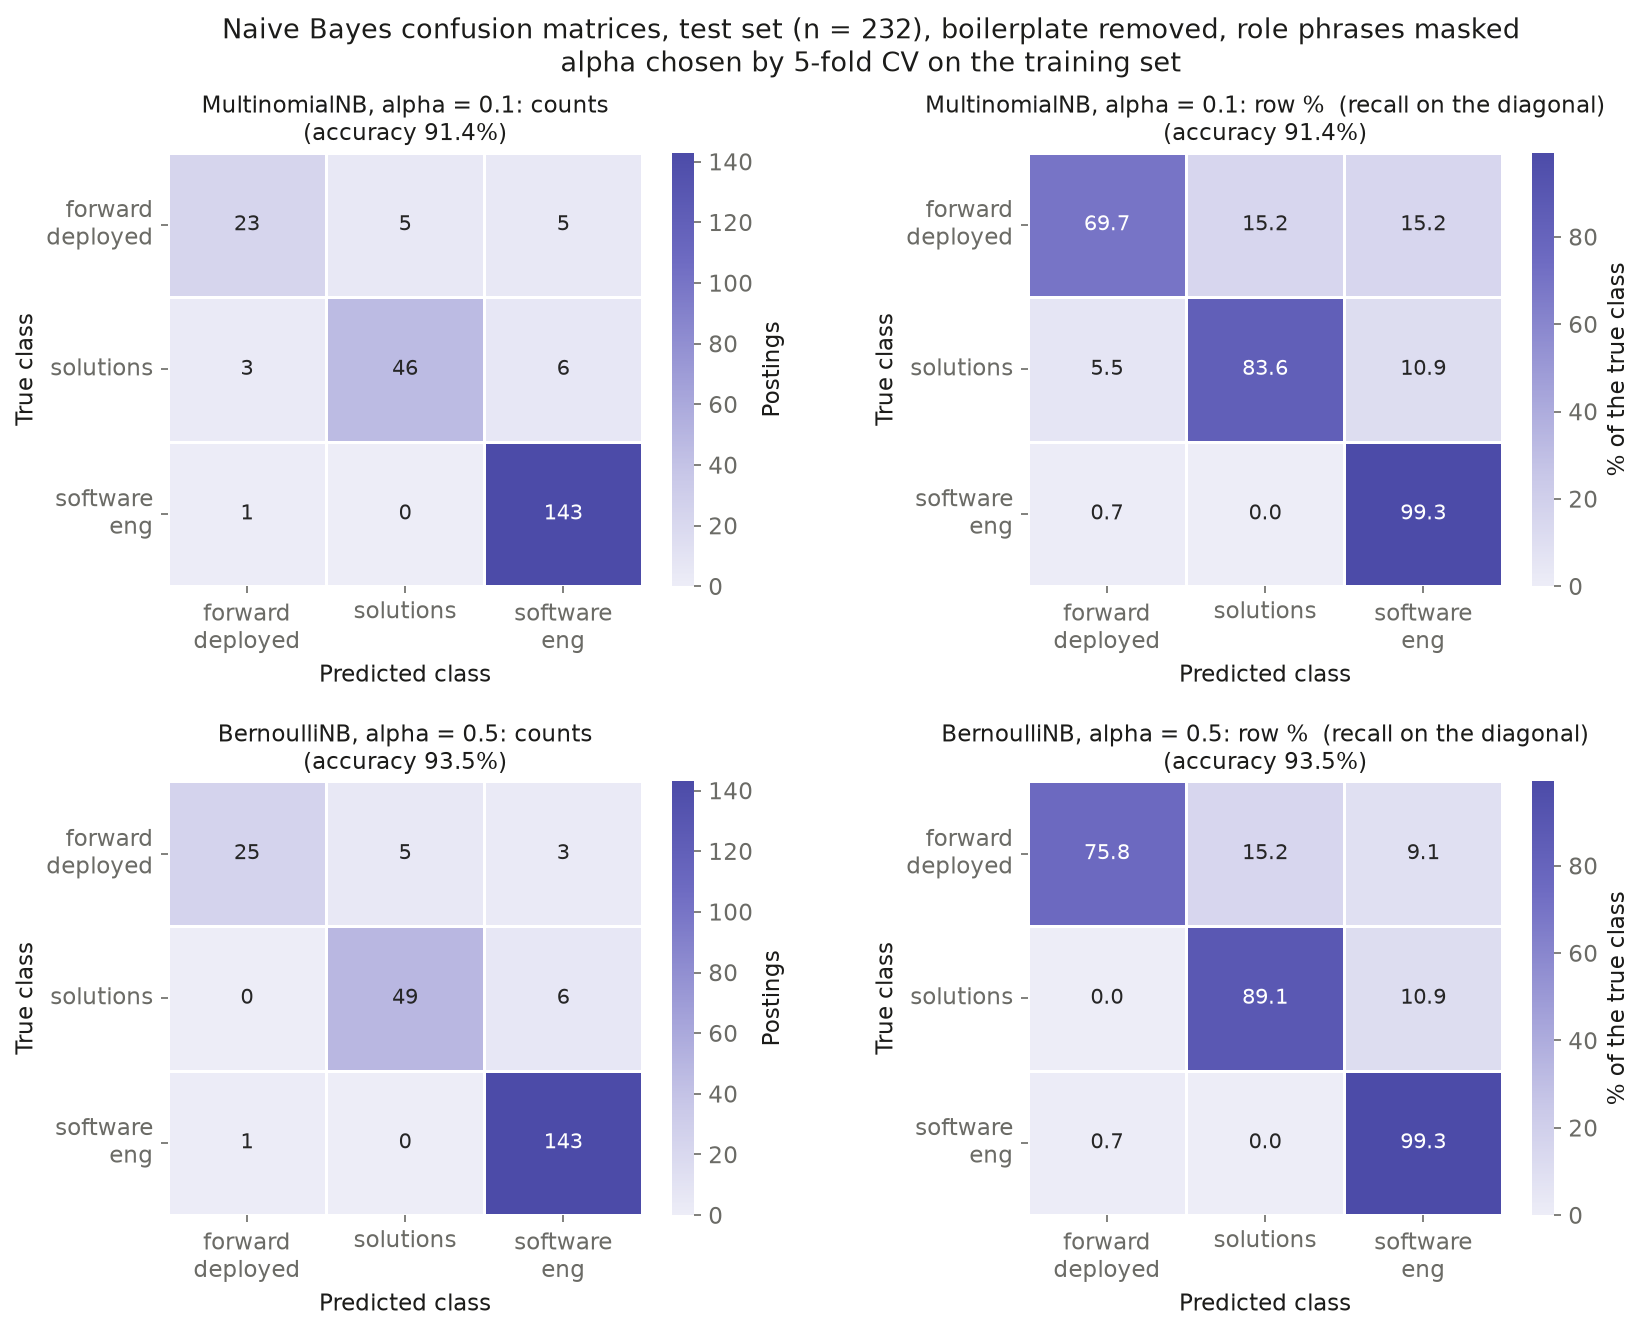

In [12]:
fig = nb.plot_confusion(results["masked"], nb.LABEL["masked"])
save(fig, "nb_confusion_masked")

## Insight
Hiding job titles and role names barely changes the result (91.4% and 93.5%). The models read the work described, not the name of the job.

### Accuracy across text variants

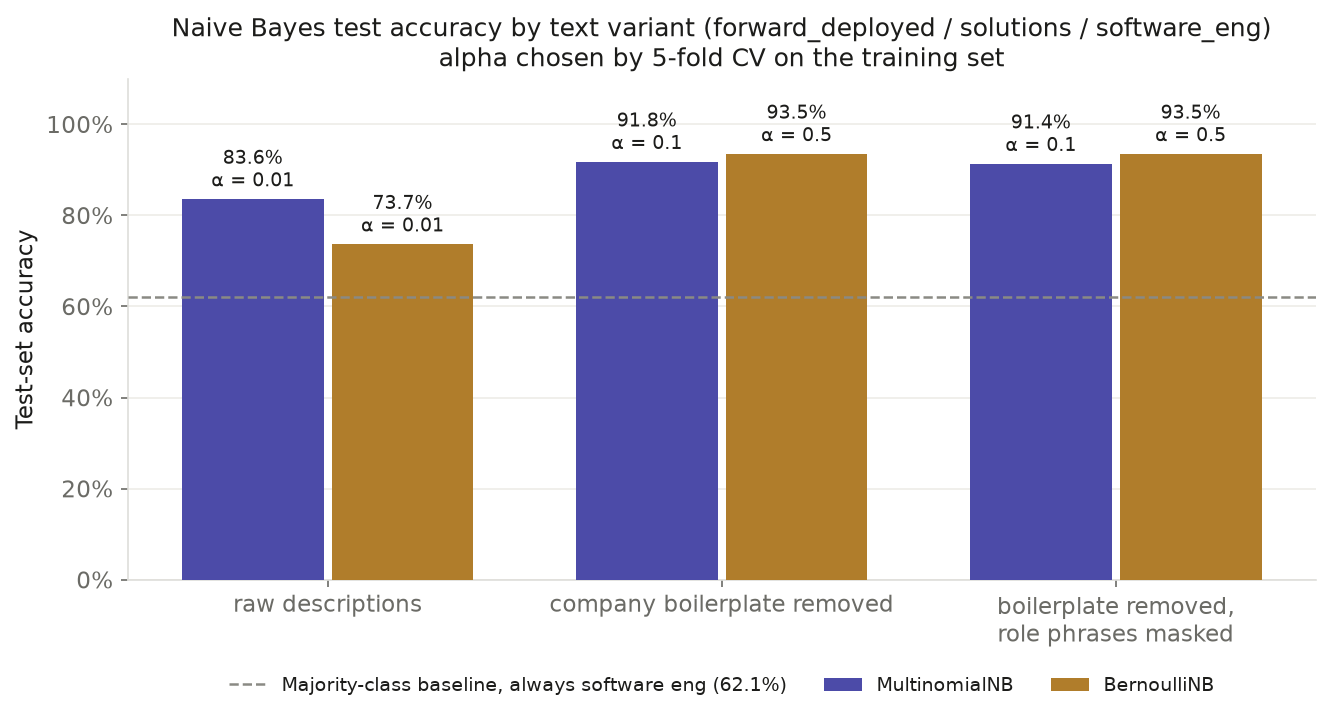

In [13]:
fig = nb.plot_accuracy(accuracy, selected_alpha, baseline)
save(fig, "nb_accuracy_compare")

## Insight
Every model beats the 62.1% baseline. Removing repeated company text helps most, and hiding role names changes accuracy by less than half a point.

### What the masked MultinomialNB learned

,forward_deployed,solutions,software_eng
1,customer (-4.700),data (-4.689),infrastructure (-5.013)
2,data (-5.059),customer (-4.761),data (-5.173)
3,customers (-5.090),customers (-5.052),ai (-5.326)
4,ai (-5.126),sales (-5.089),product (-5.454)
5,end (-5.253),account (-5.305),scale (-5.615)
6,work (-5.377),platform (-5.540),platform (-5.653)
7,engineering (-5.440),product (-5.550),security (-5.680)
8,delivery (-5.517),solutions (-5.589),building (-5.691)
9,production (-5.520),strategy (-5.692),engineering (-5.730)
10,projects (-5.579),ai (-5.697),work (-5.757)


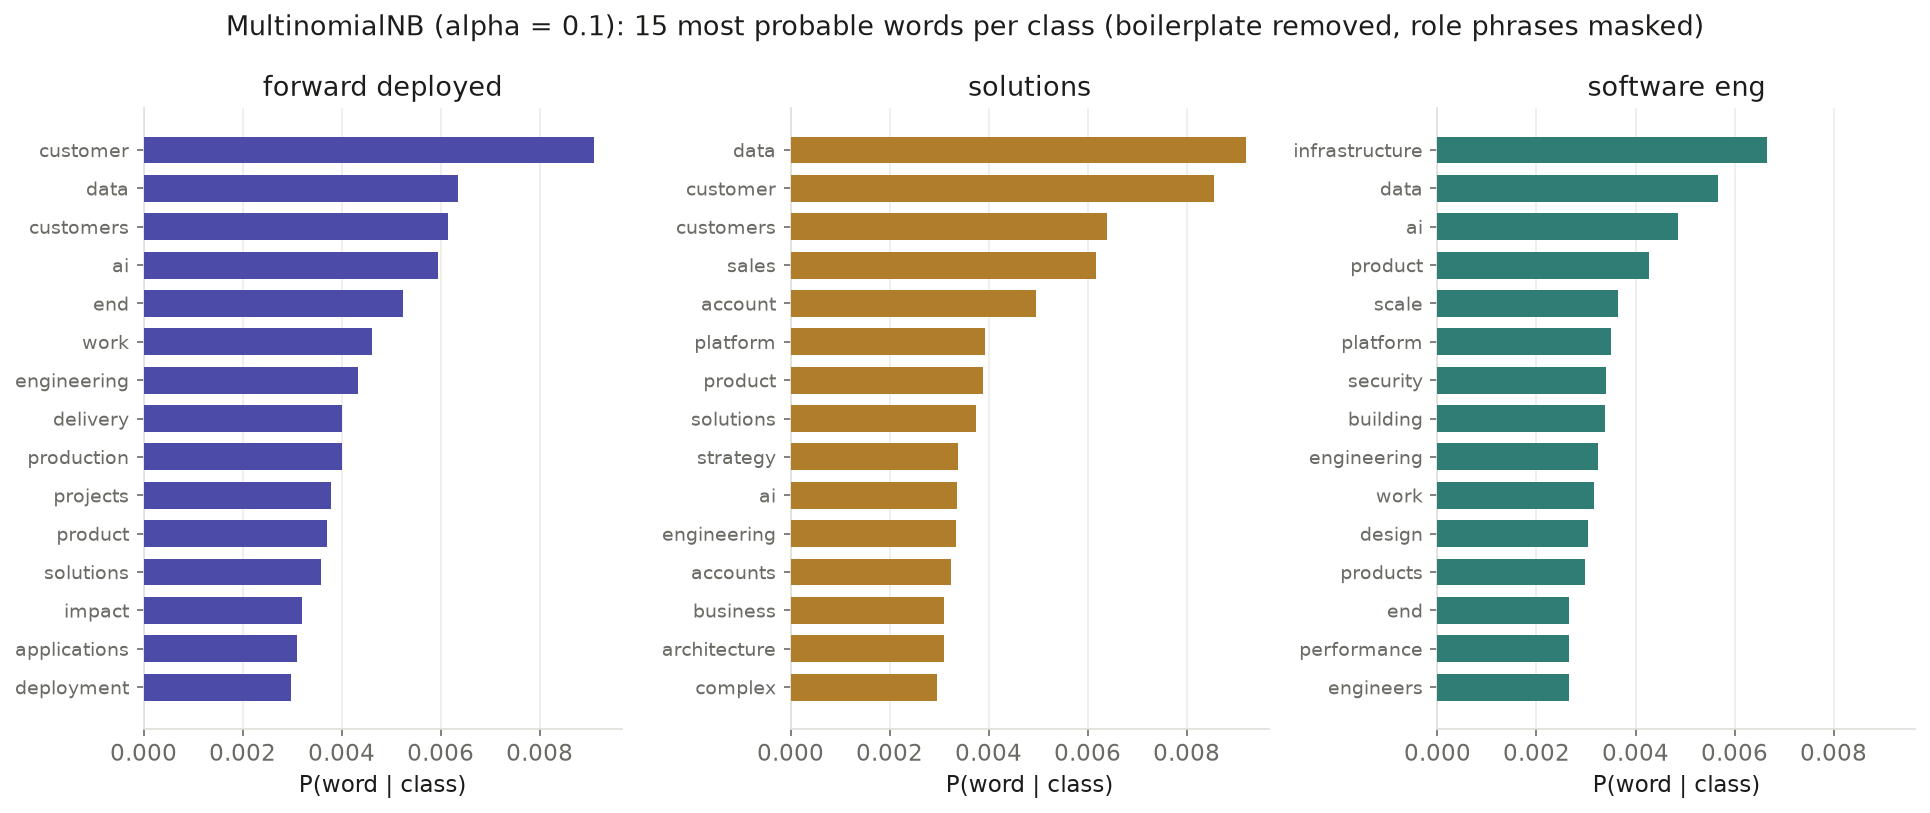

In [14]:
mnb = results["masked"]["MultinomialNB"]
words = nb.top_words(mnb["model"], mnb["vectorizer"])
display(pd.DataFrame({c: [f"{w} ({lp:.3f})" for w, lp in s.items()] for c, s in words.items()},
                     index=range(1, 16)))
fig = nb.plot_top_words(words, nb.LABEL["masked"], mnb["alpha"])
save(fig, "nb_top_words_masked")

## Insight
The most common words, such as data, ai and product, appear in all three roles. They show what each role talks about, not what makes it different.

In [15]:
# training postings per company in each class: how many employers each class's vocabulary can come from
train_rows = df.iloc[train]
class_companies = pd.crosstab(train_rows.company_clean, train_rows.role_family).reindex(columns=nb.CLASSES)
class_companies = class_companies.loc[class_companies.sum(axis=1).sort_values(ascending=False).index]
print("distinct companies with training postings in the class:", (class_companies > 0).sum().to_dict())
display(class_companies)

distinct companies with training postings in the class: {'forward_deployed': 10, 'solutions': 14, 'software_eng': 18}


role_family,forward_deployed,solutions,software_eng
company_clean,,,
Databricks,48,146,116
OpenAI,11,14,131
Anthropic,3,8,87
Palantir,37,11,30
Scale AI,12,4,35
Cohere,15,6,15
Harvey,0,2,30
Sierra,0,0,32
Perplexity,1,0,23


In [16]:
# log-probability lead over the next most likely class (masked MultinomialNB), three lists:
#   unfiltered        diagnostic; it is what surfaced fdse and the pay-band numbers
#   class df >= 10    words in at least LEAD_MIN_CLASS_DF training postings of the class
#   companies >= 3    words in training postings of the class from at least
#                     LEAD_MIN_COMPANIES distinct companies (shown in the figure)
# all counts are on the training rows; the vectoriser's own min_df is unchanged
X_text, y_train, co_train = TEXTS["masked"].iloc[train], y.iloc[train], df.company_clean.iloc[train]
leads = nb.lead_table(mnb["model"], mnb["vectorizer"],
                      nb.class_doc_freq(mnb["vectorizer"], X_text, y_train),
                      nb.class_company_count(mnb["vectorizer"], X_text, y_train, co_train))
LEAD_LISTS = {"unfiltered": (0, 0),
              f"class df >= {nb.LEAD_MIN_CLASS_DF}": (nb.LEAD_MIN_CLASS_DF, 0),
              f"companies >= {nb.LEAD_MIN_COMPANIES}": (0, nb.LEAD_MIN_COMPANIES)}
lead = {k: nb.distinctive_words(leads, *floors) for k, floors in LEAD_LISTS.items()}
BREADTH = list(LEAD_LISTS)[2]

def lead_entries(t):
    return [f"{w} (+{v:.2f}, df {d}, {k} cos)" for w, v, d, k in zip(t.index, t["lead"], t["class_df"], t["companies"])]

for c in nb.CLASSES:
    print(c)
    display(pd.DataFrame({k: lead_entries(lead[k][c]) for k in lead}, index=range(1, 16)))

forward_deployed


,unfiltered,class df >= 10,companies >= 3
1,"conflicts (+3.37, df 26, 1 cos)","conflicts (+3.37, df 26, 1 cos)","delivered (+2.26, df 35, 4 cos)"
2,"immersion (+3.37, df 26, 1 cos)","immersion (+3.37, df 26, 1 cos)","embed (+2.04, df 48, 8 cos)"
3,"bootstrap (+3.26, df 26, 1 cos)","bootstrap (+3.26, df 26, 1 cos)","country (+2.01, df 7, 3 cos)"
4,"coder (+3.14, df 18, 2 cos)","coder (+3.14, df 18, 2 cos)","measurable (+2.00, df 45, 4 cos)"
5,"billable (+2.95, df 30, 1 cos)","billable (+2.95, df 30, 1 cos)","exceed (+1.95, df 10, 3 cos)"
6,"wrangling (+2.94, df 14, 1 cos)","wrangling (+2.94, df 14, 1 cos)","empathy (+1.76, df 26, 3 cos)"
7,"entrusted (+2.94, df 6, 1 cos)","wildfire (+2.90, df 15, 1 cos)","stakes (+1.71, df 42, 5 cos)"
8,"wildfire (+2.90, df 15, 1 cos)","experiential (+2.89, df 13, 1 cos)","codify (+1.70, df 12, 4 cos)"
9,"experiential (+2.89, df 13, 1 cos)","teachers (+2.89, df 13, 1 cos)","priorities (+1.68, df 58, 7 cos)"
10,"teachers (+2.89, df 13, 1 cos)","entrepreneur (+2.76, df 10, 1 cos)","externally (+1.64, df 25, 4 cos)"


solutions


,unfiltered,class df >= 10,companies >= 3
1,"champions (+3.21, df 48, 3 cos)","champions (+3.21, df 48, 3 cos)","champions (+3.21, df 48, 3 cos)"
2,"ex (+3.04, df 15, 2 cos)","ex (+3.04, df 15, 2 cos)","demo (+2.95, df 53, 6 cos)"
3,"specialization (+3.04, df 24, 2 cos)","specialization (+3.04, df 24, 2 cos)","workshops (+2.92, df 74, 8 cos)"
4,"demo (+2.95, df 53, 6 cos)","demo (+2.95, df 53, 6 cos)","demonstrations (+2.92, df 22, 4 cos)"
5,"workshops (+2.92, df 74, 8 cos)","workshops (+2.92, df 74, 8 cos)","prospects (+2.80, df 16, 4 cos)"
6,"demonstrations (+2.92, df 22, 4 cos)","demonstrations (+2.92, df 22, 4 cos)","proofs (+2.73, df 53, 3 cos)"
7,"screen (+2.88, df 19, 1 cos)","screen (+2.88, df 19, 1 cos)","makers (+2.68, df 27, 4 cos)"
8,"prospects (+2.80, df 16, 4 cos)","prospects (+2.80, df 16, 4 cos)","demos (+2.60, df 52, 9 cos)"
9,"archetype (+2.76, df 15, 1 cos)","archetype (+2.76, df 15, 1 cos)","presentations (+2.46, df 24, 6 cos)"
10,"territory (+2.76, df 33, 2 cos)","territory (+2.76, df 33, 2 cos)","win (+2.44, df 30, 4 cos)"


software_eng


,unfiltered,class df >= 10,companies >= 3
1,"query (+2.78, df 37, 11 cos)","query (+2.78, df 37, 11 cos)","query (+2.78, df 37, 11 cos)"
2,"fleet (+2.71, df 54, 10 cos)","fleet (+2.71, df 54, 10 cos)","fleet (+2.71, df 54, 10 cos)"
3,"compute (+2.54, df 112, 13 cos)","compute (+2.54, df 112, 13 cos)","compute (+2.54, df 112, 13 cos)"
4,"thousands (+2.53, df 65, 14 cos)","thousands (+2.53, df 65, 14 cos)","thousands (+2.53, df 65, 14 cos)"
5,"experiences (+2.49, df 113, 16 cos)","experiences (+2.49, df 113, 16 cos)","experiences (+2.49, df 113, 16 cos)"
6,"device (+2.48, df 34, 9 cos)","device (+2.48, df 34, 9 cos)","device (+2.48, df 34, 9 cos)"
7,"bs (+2.45, df 60, 3 cos)","bs (+2.45, df 60, 3 cos)","bs (+2.45, df 60, 3 cos)"
8,"detection (+2.43, df 69, 14 cos)","detection (+2.43, df 69, 14 cos)","detection (+2.43, df 69, 14 cos)"
9,"researchers (+2.42, df 75, 7 cos)","researchers (+2.42, df 75, 7 cos)","researchers (+2.42, df 75, 7 cos)"
10,"especially (+2.39, df 57, 13 cos)","especially (+2.39, df 57, 13 cos)","especially (+2.39, df 57, 13 cos)"


,forward_deployed,solutions,software_eng
vocabulary,3631,3631,3631
in class (df >= 1),2201,2717,3469
"in class, companies >= 3",745,1235,2721
favouring the class (lead > 0),894,1031,1705
"favouring, companies >= 3",304,531,1448


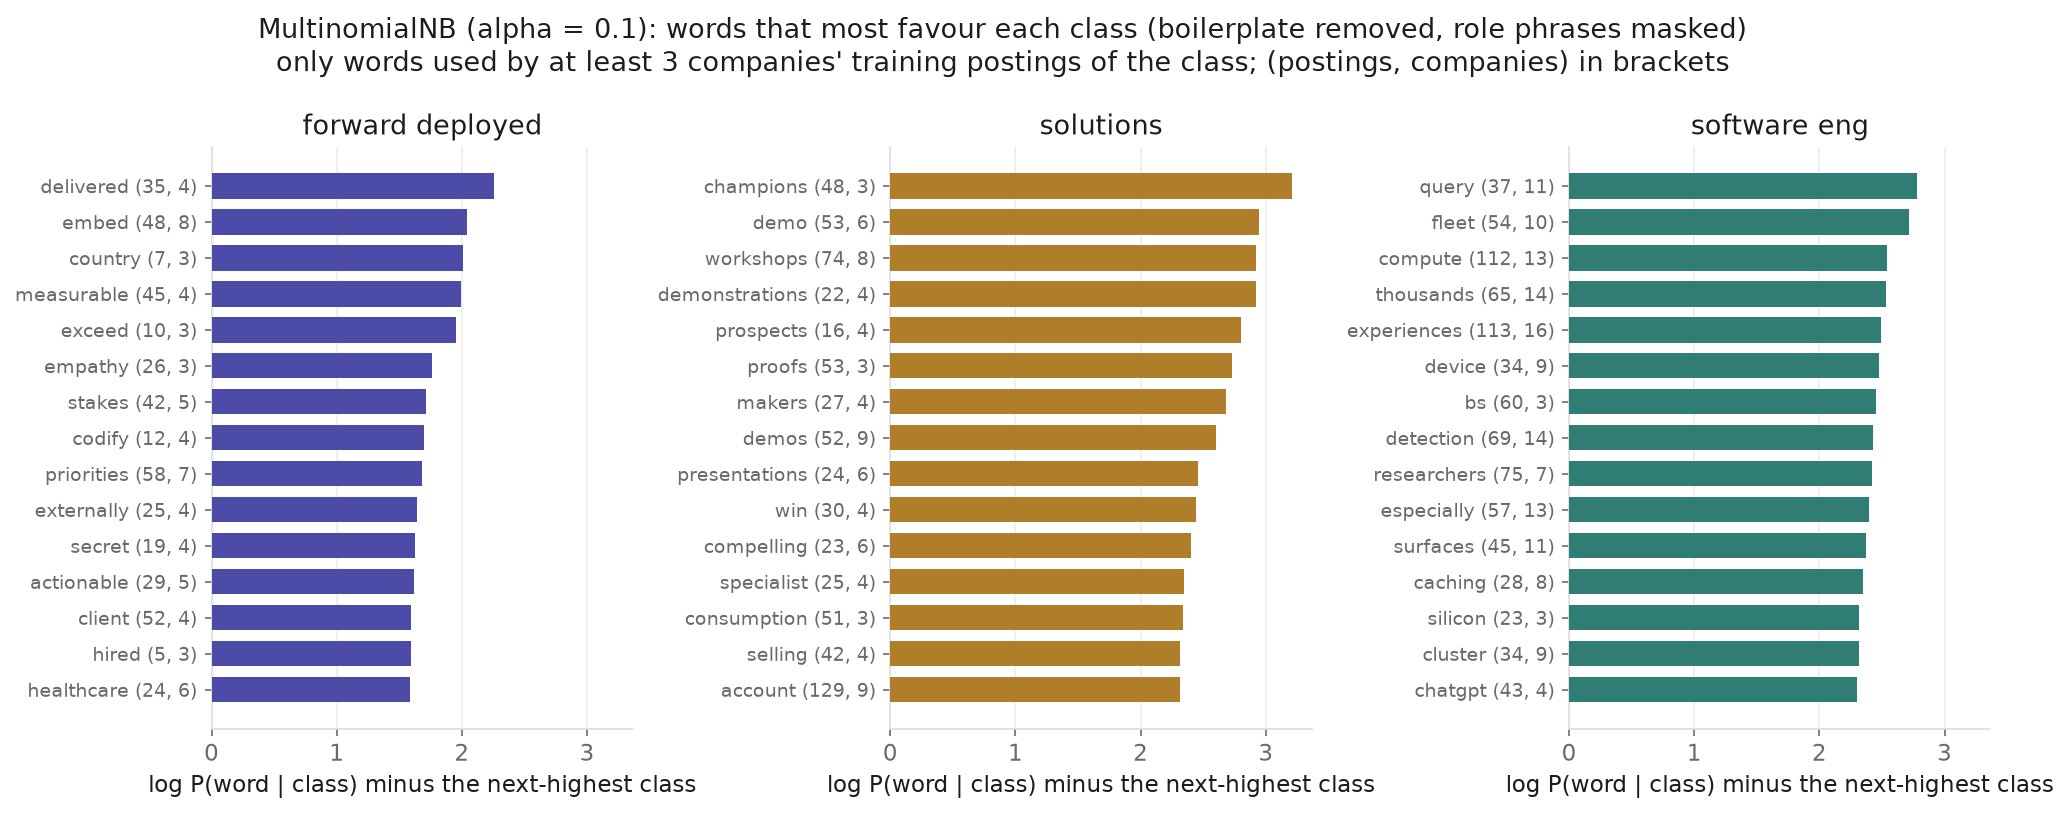

In [17]:
# vocabulary words eligible for each class's list (in >= 1 training posting of the class),
# and how many of them meet the company-breadth floor; "favouring" = lead > 0
eligibility = pd.DataFrame({c: {
    "vocabulary": len(t),
    "in class (df >= 1)": int((t.class_df >= 1).sum()),
    f"in class, companies >= {nb.LEAD_MIN_COMPANIES}": int((t.companies >= nb.LEAD_MIN_COMPANIES).sum()),
    "favouring the class (lead > 0)": int(((t.class_df >= 1) & (t.lead > 0)).sum()),
    f"favouring, companies >= {nb.LEAD_MIN_COMPANIES}": int(((t.companies >= nb.LEAD_MIN_COMPANIES) & (t.lead > 0)).sum()),
} for c, t in leads.items()})
display(eligibility)
fig = nb.plot_lead_words(lead[BREADTH], nb.LABEL["masked"], mnb["alpha"], nb.LEAD_MIN_COMPANIES)
save(fig, "nb_lead_words_masked")

## Insight
Words used by at least 3 companies that set each role apart: delivered and embed for forward_deployed, champions and demo for solutions, and query and fleet for software_eng.

In [18]:
# the pay-band numbers that were distinctive before the letter-required token pattern;
# they are still in the text but no longer in the vocabulary
token_lines = []
for tok in NUMBER_TOKENS:
    hit, examples = nb.token_postings(TEXTS["masked"], df, tok)
    in_test = hit.iloc[test].sum()
    token_lines += [f"'{tok}': {hit.sum()} postings (train {hit.sum() - in_test}, test {in_test})",
                    "  by class: " + str(y[hit].value_counts().reindex(nb.CLASSES, fill_value=0).to_dict()),
                    "  by company: " + str(df.company_clean[hit].value_counts().to_dict()),
                    *[f"  {e}" for e in examples]]
band = TEXTS["masked"].str.contains("$182,000-$250,208", regex=False)
token_lines += [f"postings containing the band '$182,000-$250,208 USD': {band.sum()} "
                f"({y[band].value_counts().to_dict()}; companies {df.company_clean[band].unique().tolist()})",
                f"  repeats per posting: median {TEXTS['masked'][band].str.count(r'182,000').median():.0f}"]
print("\n".join(token_lines))

'182': 25 postings (train 18, test 7)
  by class: {'forward_deployed': 19, 'solutions': 1, 'software_eng': 5}
  by company: {'Databricks': 25}
  [Databricks | forward_deployed | AI Engineer - FDE (Forward Deployed Engineer) - U.S. Federal Sector] ...nce every 4-8 weeks to see customers (as needed) $182,000-$250,208 USD...
  [Databricks | solutions | Deployment Strategist] ...s, and the ability/interest to travel up to 50%. $182,000-$250,208 USD $182,000-$250,208 USD $182,000-$...
  [Databricks | forward_deployed | Sr. Delivery Partner Manager, FDE] ...,000-$214,500 USD $140,400-$193,050 USD $132,600-$182,400 USD $124,800-$171,600 USD...
'208': 22 postings (train 17, test 5)
  by class: {'forward_deployed': 17, 'solutions': 1, 'software_eng': 4}
  by company: {'Databricks': 18, 'Vercel': 4}
  [Databricks | forward_deployed | AI Engineer - FDE (Forward Deployed Engineer) - U.S. Federal Sector] ... weeks to see customers (as needed) $182,000-$250,208 USD...
  [Databricks | solutions | Dep

## Insight
The numbers that looked important were salary bands, mostly from Databricks, not job content. So numbers are left out of the vocabulary.

In [19]:
errors = nb.confident_errors(mnb["model"], mnb["X_test"], df.iloc[test], TEXTS["masked"].iloc[test])
print(f"misclassified test postings: {(mnb['pred'] != y.iloc[test].values).sum()} of {len(test)}")
for i, e in errors.iterrows():
    print(f"\n{i + 1}. true {e.true} -> predicted {e.predicted} (p = {e.confidence:.3f}) "
          f"| {e.company_clean} | {e.title} | jobId {e.jobId}\n   {e.text!r}")

misclassified test postings: 20 of 232

1. true software_eng -> predicted forward_deployed (p = 0.999) | Palantir | Year at Palantir - Software Engineer, Internship | jobId 655f9937-a4ce-4e7d-80e2-a6659af07329
   "Year We've had surging demand from undergrads who want to get into the arena faster. You've told us you can't sit in lectures while the biggest story "

2. true solutions -> predicted software_eng (p = 0.997) | Webflow | Staff DevOps Engineer, Delivery Loop | jobId 7942745
   "We're hiring a Staff , Developer Productivity to define and drive the future of how engineers build, test, and deliver software. In this role, you'll "

3. true solutions -> predicted software_eng (p = 0.978) | Databricks | Sr Technical Solutions Engineering | jobId 8589172002
   'Founded by engineers - and customer obsessed - we leap at every opportunity to solve technical challenges, from designing next-gen UI/UX for interfaci'

4. true forward_deployed -> predicted software_eng (p = 0.976) | OpenAI |

## Insight
Multinomial NB gets 20 of 232 test postings wrong. Some are label problems: titles with "Delivery" are labelled solutions, but the model reads them as software_eng.

In [20]:
# diagnostic: masked-variant test accuracy by company, both models at the CV-selected alpha
by_company = pd.concat({m: nb.company_accuracy(r, df.iloc[test])
                        for m, r in results["masked"].items()}, axis=1)
by_company = pd.concat([by_company["MultinomialNB"].drop(columns="accuracy"),
                        by_company.xs("accuracy", axis=1, level=1)], axis=1)
by_company.columns = [*by_company.columns[:-2], *[f"accuracy {m} (alpha = {results['masked'][m]['alpha']})"
                                                  for m in results["masked"]]]
by_company["software_eng share"] = by_company["software_eng"] / by_company["n_test"]
by_company.round(3)

,n_test,forward_deployed,solutions,software_eng,accuracy MultinomialNB (alpha = 0.1),accuracy BernoulliNB (alpha = 0.5),software_eng share
company,,,,,,,
Databricks,75,13,30,32,0.933,0.933,0.427
OpenAI,45,6,5,34,0.933,0.933,0.756
Anthropic,14,0,0,14,1.000,1.000,1.000
Palantir,14,5,2,7,0.857,0.857,0.500
Scale AI,11,3,2,6,0.727,0.909,0.545
Harvey,9,0,2,7,1.000,1.000,0.778
Ramp,9,1,1,7,0.889,0.889,0.778
Cohere,8,3,5,0,0.750,1.000,0.000
Stripe,7,0,0,7,1.000,1.000,1.000


## Insight
Accuracy stays high across companies. Databricks, which has the most mixed set of jobs, is still 93.3% correct for both models.

### Outputs

In [21]:
def block(title, frame):
    return [title, *[f"  {line}" for line in frame.to_string().splitlines()]]

report += ["", "ACCURACY SUMMARY",
           *block(f"alpha selected by {nb.CV_FOLDS}-fold stratified CV on the training rows:", selected_alpha),
           *block("HEADLINE test accuracy at the selected alpha:", accuracy.round(4)),
           f"  majority-class baseline ({baseline[0]}): {baseline[1]:.4f}",
           *block("for comparison, test accuracy at alpha = 1.0 (sklearn default):", default_accuracy.round(4)),
           *block("CV accuracy on the training rows (mean, sd over folds):", cv_table.round(4).unstack("alpha")),
           *block("SENSITIVITY ONLY, test accuracy by alpha (not used to choose alpha):", test_sweep.round(4))]
report += ["", f"MULTINOMIALNB (alpha = {mnb['alpha']}), MASKED VARIANT: top 15 words by log P(word | class)"]
for c, s in words.items():
    report.append(f"  {c}: " + ", ".join(f"{w} ({lp:.3f})" for w, lp in s.items()))
report += ["", "LOG-PROBABILITY LEAD OVER THE NEXT MOST LIKELY CLASS (masked MultinomialNB; training rows; "
           "df = training postings of the class containing the word, cos = distinct companies among them)",
           *block("training postings per company and class:", class_companies),
           "  distinct companies per class: " + str((class_companies > 0).sum().to_dict()),
           *block("vocabulary words eligible, and meeting the company-breadth floor:", eligibility)]
for k, title in [(BREADTH, f"COMPANY-BREADTH list (>= {nb.LEAD_MIN_COMPANIES} distinct companies; "
                           "the list in nb_lead_words_masked.png):"),
                 (f"class df >= {nb.LEAD_MIN_CLASS_DF}", f"DOCUMENT-FREQUENCY list (>= {nb.LEAD_MIN_CLASS_DF} "
                                                          "training postings of the class):"),
                 ("unfiltered", "DIAGNOSTIC, UNFILTERED list (no floor; this is the list that surfaced fdse "
                                "and the pay-band numbers):")]:
    report.append(title)
    for c in nb.CLASSES:
        report.append(f"  {c}: " + ", ".join(lead_entries(lead[k][c])))
report += ["", "PAY-BAND NUMBER TOKENS (still in the text; excluded from the vocabulary by the token pattern)",
           *[f"  {line}" for line in token_lines]]
report += ["", "DIAGNOSTIC: masked-variant test accuracy by company",
           *[f"  {line}" for line in by_company.round(3).to_string().splitlines()]]
report += ["", "10 MOST CONFIDENTLY WRONG TEST POSTINGS (masked text, first 150 characters)"]
for i, e in errors.iterrows():
    report += [f"  {i + 1}. true {e.true} -> predicted {e.predicted} (p = {e.confidence:.4f}) "
               f"| {e.company_clean} | {e.title} | jobId {e.jobId}", f"     {e.text!r}"]

nb.REPORT_PATH.parent.mkdir(exist_ok=True)
nb.REPORT_PATH.write_text("\n".join(report) + "\n")
print(f"wrote {nb.REPORT_PATH.relative_to(tc.ROOT)} ({len(report)} lines)")

wrote results/nb_report.txt (510 lines)


## 2. Decision Trees

### Features

In [22]:
from src import role_dt as dt

# same 1,159 postings, same split as Naive Bayes (train, test from nb.split_rows above)
dt_report = []  # lines for results/dt_report.txt
X_tab = dt.tabular_frame(df)
X_by_tree = {t: (TEXTS["masked"] if t == "tree4" else X_tab) for t in dt.TREES}
print(f"rows: {len(df)}, train {len(train)}, test {len(test)}, jobId overlap: "
      f"{len(set(df.jobId.iloc[train]) & set(df.jobId.iloc[test]))}")
print("never used as features:")
for col, why in dt.EXCLUDED.items():
    print(f"  {col}: {why}")
for t, (label, cols) in dt.TREES.items():
    print(f"{t} ({label}): {cols if cols else 'masked-text TF-IDF, same vectoriser as masked Naive Bayes'}")
dt_report += ["DATA", f"  rows {len(df)}, train {len(train)}, test {len(test)}, jobId overlap "
              f"{len(set(df.jobId.iloc[train]) & set(df.jobId.iloc[test]))}",
              "  never used as features: " + "; ".join(f"{c} ({w})" for c, w in dt.EXCLUDED.items()),
              *[f"  {t} ({label}): {cols if cols else 'masked-text TF-IDF'}" for t, (label, cols) in dt.TREES.items()]]

rows: 1159, train 927, test 232, jobId overlap: 0
never used as features:
  role_family: the target
  title: the label is parsed from it
  seniority: parsed from the title by the same keyword rule
  is_near_dup: near-duplicate flag; its key includes the normalised title
tree1 (all tabular features): ['department', 'company_clean', 'location_clean', 'workplaceType', 'salary_annual_min', 'salary_annual_max', 'desc_len', 'location_count', 'is_multi_location']
tree2 (department removed): ['company_clean', 'location_clean', 'workplaceType', 'salary_annual_min', 'salary_annual_max', 'desc_len', 'location_count', 'is_multi_location']
tree3 (department and company removed): ['location_clean', 'workplaceType', 'salary_annual_min', 'salary_annual_max', 'desc_len', 'location_count', 'is_multi_location']
tree4 (masked text TF-IDF): masked-text TF-IDF, same vectoriser as masked Naive Bayes


In [23]:
# missing fraction per feature (suspect salaries counted as missing), and categories
# in the test rows that never occur in the training rows
missing = pd.DataFrame({"all rows": X_tab.isna().mean(), "train": X_tab.iloc[train].isna().mean(),
                        "test": X_tab.iloc[test].isna().mean()}).mul(100).round(2)
missing["distinct values"] = X_tab.nunique()
display(missing)
unseen = {c: int((~X_tab[c].iloc[test].fillna("missing").isin(set(X_tab[c].iloc[train].fillna("missing")))).sum())
          for c in dt.CATEGORICAL}
print("test rows whose category is unseen in training (encoded as all zeros for that column):", unseen)
print("salary: suspect values set to missing:", int(df.salary_suspect.eq(True).sum()),
      "| non-USD salaries kept as annualised values:", df.salary_currency.value_counts().drop("USD", errors="ignore").to_dict())
dt_report += ["", "MISSING VALUES (% of rows) AND HANDLING",
              *[f"  {line}" for line in missing.to_string().splitlines()],
              "  categorical: missing -> its own category 'missing', then one-hot (fitted on training rows; "
              "unseen test categories -> all-zero columns)",
              "  numeric: median imputation (fitted on training rows); one indicator 'salary missing' "
              "(salary min and max are missing on the same rows)",
              f"  test rows with a category unseen in training: {unseen}",
              f"  suspect salaries set to missing: {int(df.salary_suspect.eq(True).sum())}; non-USD salaries kept: "
              f"{df.salary_currency.value_counts().drop('USD', errors='ignore').to_dict()}"]

,all rows,train,test,distinct values
department,0.00,0.00,0.00,122
company_clean,0.00,0.00,0.00,19
location_clean,0.09,0.00,0.43,92
workplaceType,62.12,62.57,60.34,3
salary_annual_min,68.77,69.15,67.24,68
salary_annual_max,68.77,69.15,67.24,67
desc_len,0.00,0.00,0.00,1013
location_count,0.00,0.00,0.00,10
is_multi_location,0.00,0.00,0.00,2


test rows whose category is unseen in training (encoded as all zeros for that column): {'department': 16, 'company_clean': 0, 'location_clean': 7, 'workplaceType': 0}
salary: suspect values set to missing: 4 | non-USD salaries kept as annualised values: {'GBP': 11}


In [24]:
# feature count per tree after encoding (encoder / vectoriser fitted on the training rows)
n_features = {}
for t in dt.TREES:
    m = dt.make_model(t, "gini")
    n_features[t] = len(m.named_steps["features"].fit(X_by_tree[t].iloc[train], y.iloc[train]).get_feature_names_out())
    if t != "tree4":
        sources = pd.Series(dt.feature_names(m)).map(dt.source_feature).value_counts()
        print(f"{t}: {n_features[t]} features  {sources.to_dict()}")
    else:
        print(f"{t}: {n_features[t]} features (TF-IDF vocabulary)")
dt_report += ["", "FEATURES AFTER ENCODING", *[f"  {t}: {n}" for t, n in n_features.items()]]

tree1: 222 features  {'department': 107, 'location_clean': 86, 'company_clean': 19, 'workplaceType': 4, 'salary_annual_min': 1, 'salary_annual_max': 1, 'desc_len': 1, 'location_count': 1, 'is_multi_location': 1, 'salary missing (indicator)': 1}
tree2: 115 features  {'location_clean': 86, 'company_clean': 19, 'workplaceType': 4, 'salary_annual_min': 1, 'salary_annual_max': 1, 'desc_len': 1, 'location_count': 1, 'is_multi_location': 1, 'salary missing (indicator)': 1}
tree3: 96 features  {'location_clean': 86, 'workplaceType': 4, 'salary_annual_min': 1, 'salary_annual_max': 1, 'desc_len': 1, 'location_count': 1, 'is_multi_location': 1, 'salary missing (indicator)': 1}
tree4: 3631 features (TF-IDF vocabulary)


### Choosing max_depth

In [25]:
# max_depth by 5-fold stratified CV on the training rows only, as alpha was for Naive Bayes;
# each tree is fitted with criterion = gini and with criterion = entropy
dt_results = {t: dt.run_tree(X_by_tree[t], y, train, test, t) for t in dt.TREES}
cv_curves = pd.concat({(t, c): r["cv"] for t in dt_results for c, r in dt_results[t].items()},
                      names=["tree", "criterion"])
display(cv_curves.round(4).unstack("max_depth")["cv_mean"][[dt.depth_label(d) for d in dt.DEPTHS]])

max_depth             1       2       3       4       5       6       8  \
tree  criterion                                                           
tree1 entropy    0.6376  0.7044  0.7508  0.7788  0.7810  0.8295  0.8468   
      gini       0.6376  0.7163  0.7605  0.7810  0.7907  0.8274  0.8468   
tree2 entropy    0.6224  0.6947  0.7324  0.7281  0.7540  0.7766  0.7907   
      gini       0.6224  0.6925  0.7259  0.7281  0.7486  0.7734  0.7950   
tree3 entropy    0.6224  0.5922  0.6494  0.6731  0.6623  0.6817  0.7141   
      gini       0.6224  0.5965  0.6386  0.6753  0.6655  0.6763  0.7130   
tree4 entropy    0.7962  0.8641  0.8706  0.8846  0.8900  0.8943  0.8857   
      gini       0.7962  0.8706  0.8749  0.8932  0.8965  0.9008  0.9018   

max_depth            10      12      15      20    none  
tree  criterion                                          
tree1 entropy    0.8565  0.8792  0.8802  0.8878  0.8867  
      gini       0.8576  0.8845  0.8878  0.8888  0.8910  
tree2 entropy    0.7939  0.7950  0.7799  0.7831  0.7831  
      gini       0.7950  0.8015  0.7939  0.7907  0.7896  
tree3 entropy    0.7292  0.7292  0.7206  0.7335  0.7270  
      gini       0.7292  0.7325  0.7238  0.7174  0.7249  
tree4 entropy    0.8911  0.8922  0.8922  0.8922  0.8922  
      gini       0.9008  0.9029  0.9019  0.8911  0.8911

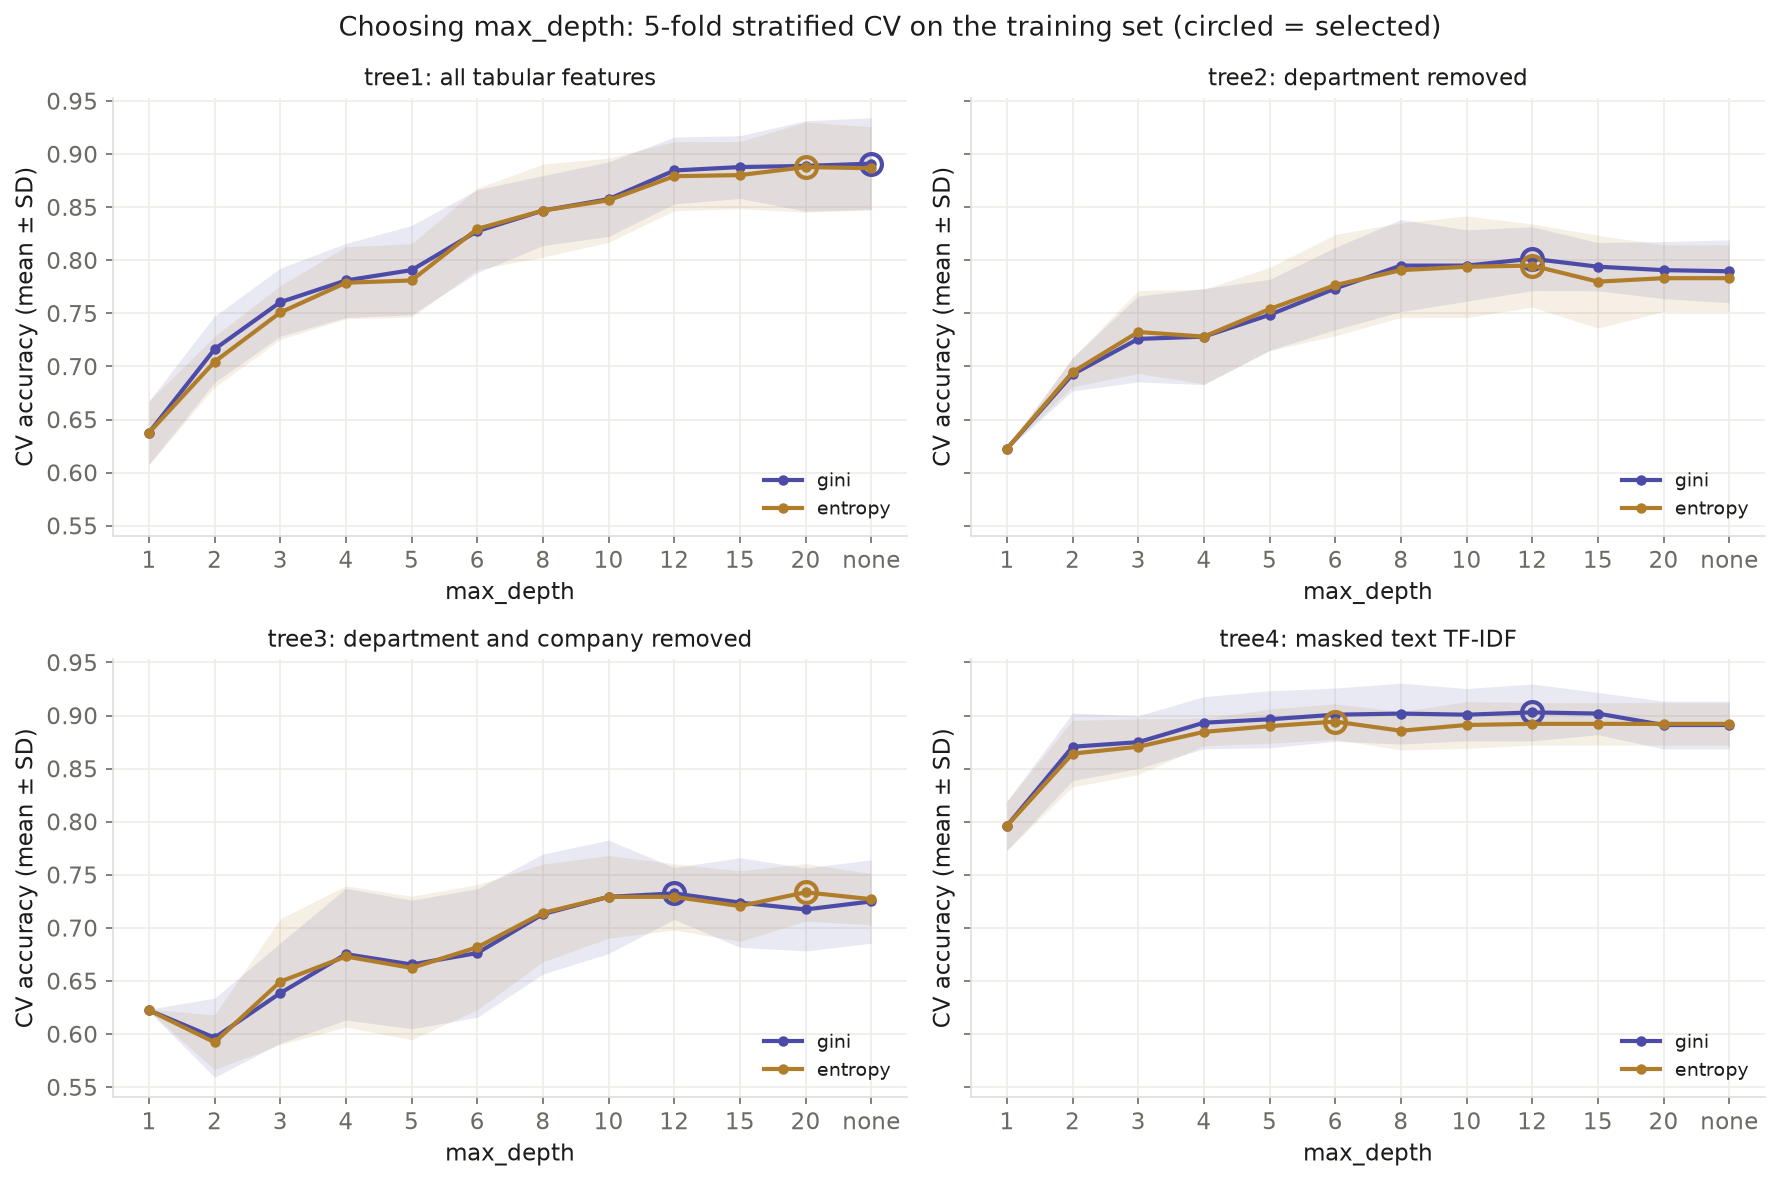

In [26]:
fig = dt.plot_cv_depth(dt_results)
save(fig, "dt_cv_depth")

## Insight
Tree 1 keeps improving all the way to no depth limit, while the other trees level off earlier. Gini and entropy give almost the same curves.

### Results

In [27]:
dt_summary = pd.DataFrame({(t, c): dt.summary_row(r) for t in dt_results for c, r in dt_results[t].items()}).T
dt_summary.index.names = ["tree", "criterion"]
print(f"majority-class baseline ({baseline[0]}): {baseline[1]:.4f}")
display(dt_summary)
mnb_acc, bnb_acc = (results["masked"][m]["accuracy"] for m in ["MultinomialNB", "BernoulliNB"])
nb_vs_dt = [f"tree 4 (masked text TF-IDF), criterion = {c}: test accuracy {r['accuracy']:.4f}"
            for c, r in dt_results["tree4"].items()]
nb_vs_dt += [f"masked MultinomialNB (alpha = {results['masked']['MultinomialNB']['alpha']}): {mnb_acc:.4f}",
             f"masked BernoulliNB (alpha = {results['masked']['BernoulliNB']['alpha']}): {bnb_acc:.4f}"]
print("\n".join(nb_vs_dt))

majority-class baseline (software_eng): 0.6207


max_depth (CV) fitted depth leaves features train accuracy  \
tree  criterion                                                              
tree1 gini                none           35    118      222            1.0   
      entropy               20           20     92      222       0.979504   
tree2 gini                  12           12    131      115        0.93959   
      entropy               12           12    133      115       0.934196   
tree3 gini                  12           12    133       96       0.899676   
      entropy               20           20    235       96       0.989213   
tree4 gini                  12           12     37     3631       0.990291   
      entropy                6            6     34     3631       0.980583   

                test accuracy train - test  macro F1  
tree  criterion                                       
tree1 gini           0.922414     0.077586  0.895533  
      entropy        0.887931     0.091573  0.853476  
tree2 gini           0.767241     0.172349  0.648304  
      entropy         0.75431     0.179886  0.633159  
tree3 gini            0.75431     0.145366  0.624168  
      entropy        0.715517     0.273695  0.622117  
tree4 gini           0.887931      0.10236  0.857069  
      entropy         0.87931     0.101272  0.835646

tree 4 (masked text TF-IDF), criterion = gini: test accuracy 0.8879
tree 4 (masked text TF-IDF), criterion = entropy: test accuracy 0.8793
masked MultinomialNB (alpha = 0.1): 0.9138
masked BernoulliNB (alpha = 0.5): 0.9353


In [28]:
for t in dt_results:
    for c, r in dt_results[t].items():
        print("\n".join(dt.result_lines(t, r, baseline)), end="\n\n")

--- tree1 (all tabular features) x criterion = gini ---
features after encoding: 222
5-fold stratified CV on the training rows (accuracy, mean +/- sd; mean training-fold accuracy):
  max_depth 1    : 0.6376 +/- 0.0299   (train folds 0.6389)
  max_depth 2    : 0.7163 +/- 0.0312   (train folds 0.7152)
  max_depth 3    : 0.7605 +/- 0.0320   (train folds 0.7611)
  max_depth 4    : 0.7810 +/- 0.0349   (train folds 0.7883)
  max_depth 5    : 0.7907 +/- 0.0421   (train folds 0.8053)
  max_depth 6    : 0.8274 +/- 0.0391   (train folds 0.8412)
  max_depth 8    : 0.8468 +/- 0.0330   (train folds 0.8770)
  max_depth 10   : 0.8576 +/- 0.0350   (train folds 0.8991)
  max_depth 12   : 0.8845 +/- 0.0315   (train folds 0.9237)
  max_depth 15   : 0.8878 +/- 0.0295   (train folds 0.9442)
  max_depth 20   : 0.8888 +/- 0.0425   (train folds 0.9717)
  max_depth none : 0.8910 +/- 0.0433   (train folds 1.0000)
selected max_depth: none (fitted depth 35, 118 leaves)
TRAIN ACCURACY: 1.0000   TEST ACCURACY: 0.92

#### Tree 1: all tabular features

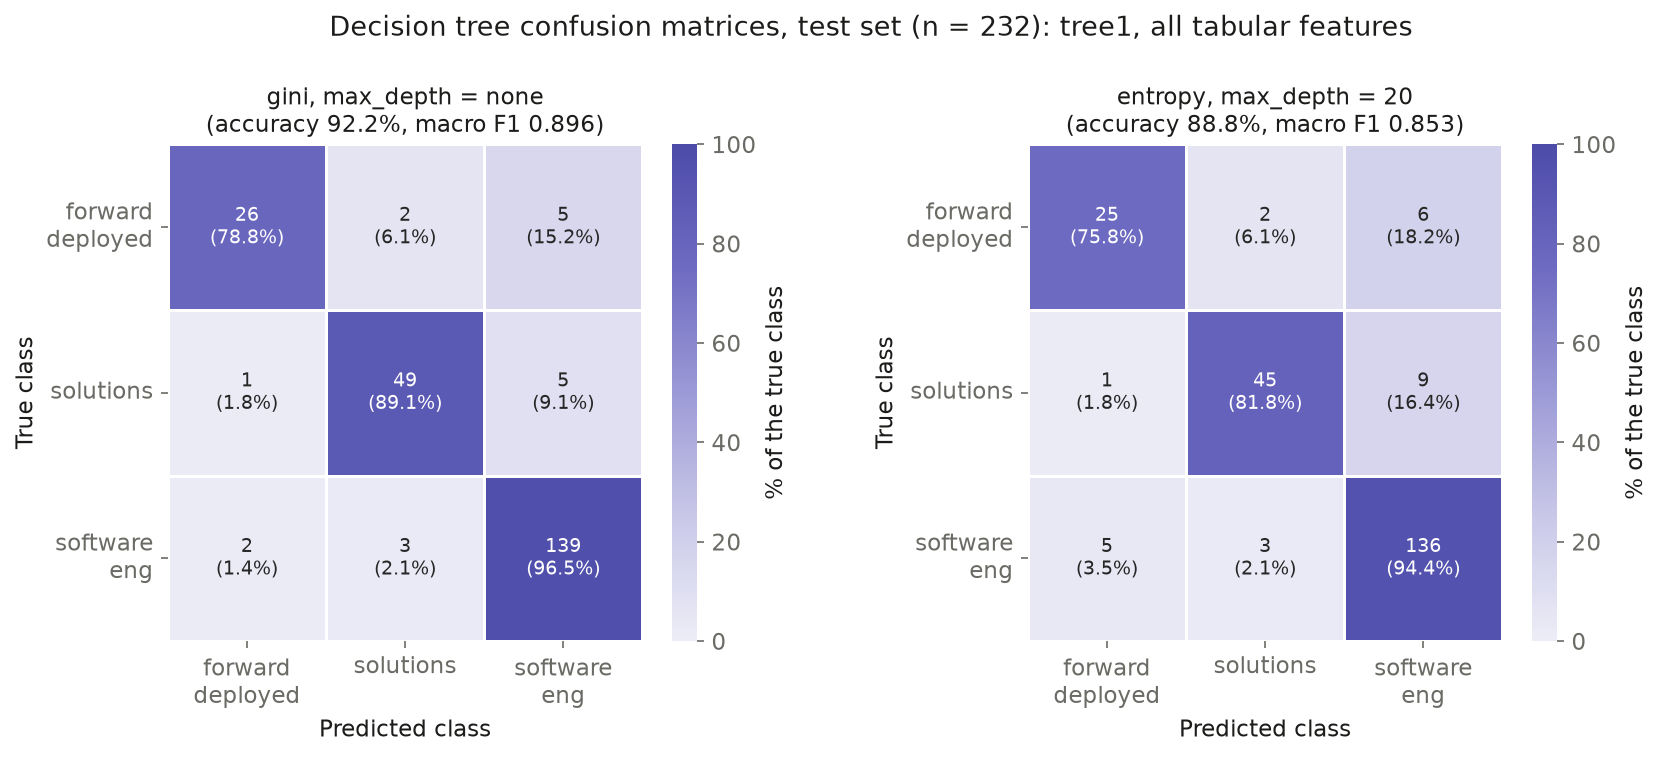

In [29]:
fig = dt.plot_confusion_dt(dt_results["tree1"], "tree1, " + dt.TREES["tree1"][0])
save(fig, "dt_confusion_tree1")

## Insight
With all features, the Gini tree gets 92.2% right and finds 26 of 33 forward_deployed postings. Department does most of the work.

#### Tree 2: department removed

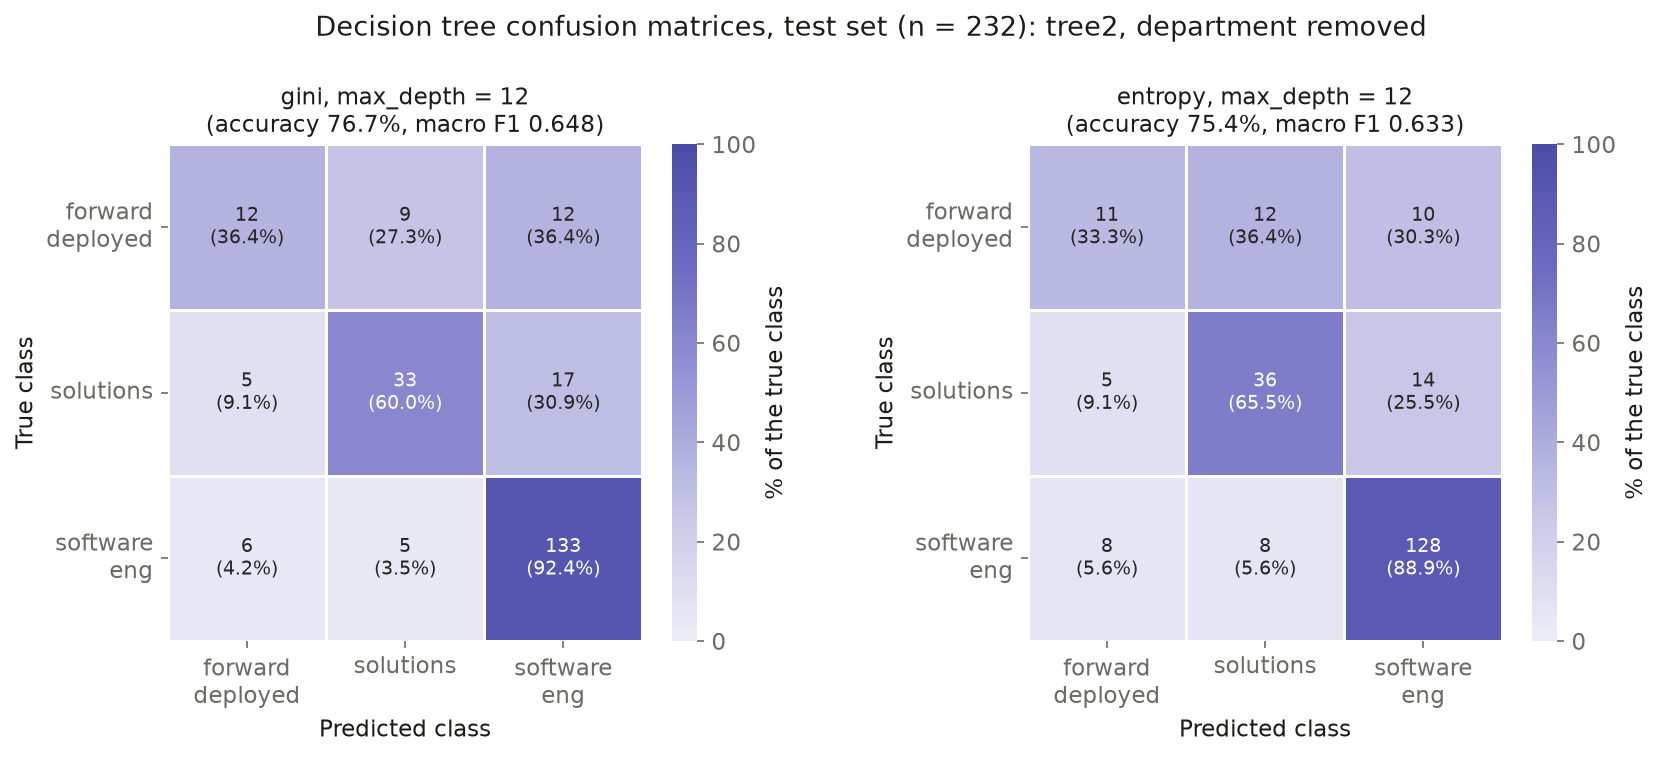

In [30]:
fig = dt.plot_confusion_dt(dt_results["tree2"], "tree2, " + dt.TREES["tree2"][0])
save(fig, "dt_confusion_tree2")

## Insight
Without department, accuracy drops to 76.7% and only 12 of 33 forward_deployed postings are found. Most misses are called software_eng.

#### Tree 3: department and company removed

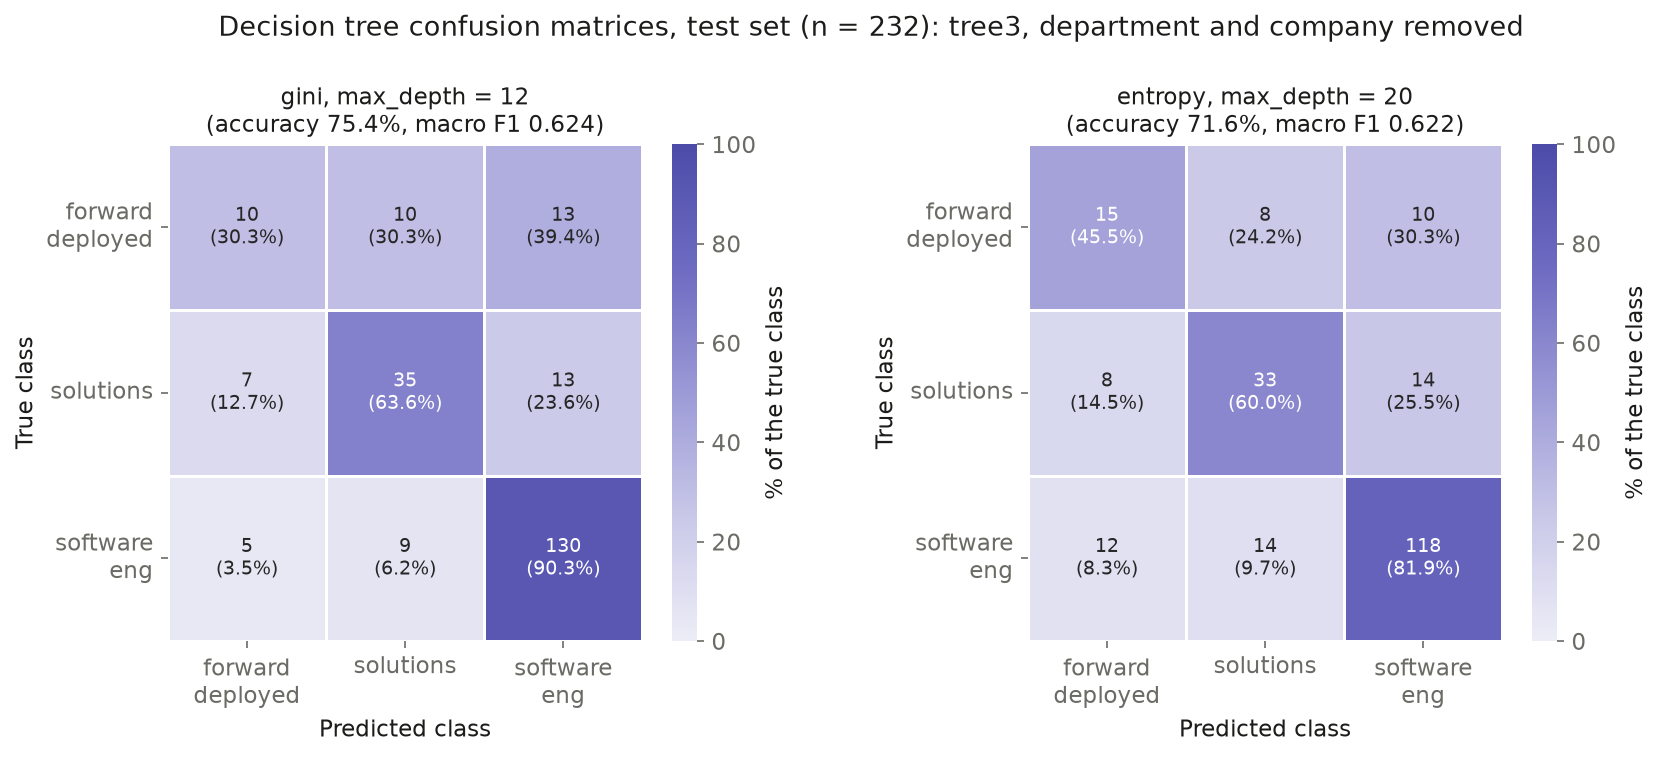

In [31]:
fig = dt.plot_confusion_dt(dt_results["tree3"], "tree3, " + dt.TREES["tree3"][0])
save(fig, "dt_confusion_tree3")

## Insight
Without department and company, accuracy is 75.4%, only 13 points above guessing. Just 10 of 33 forward_deployed postings are found.

#### Tree 4: masked text TF-IDF

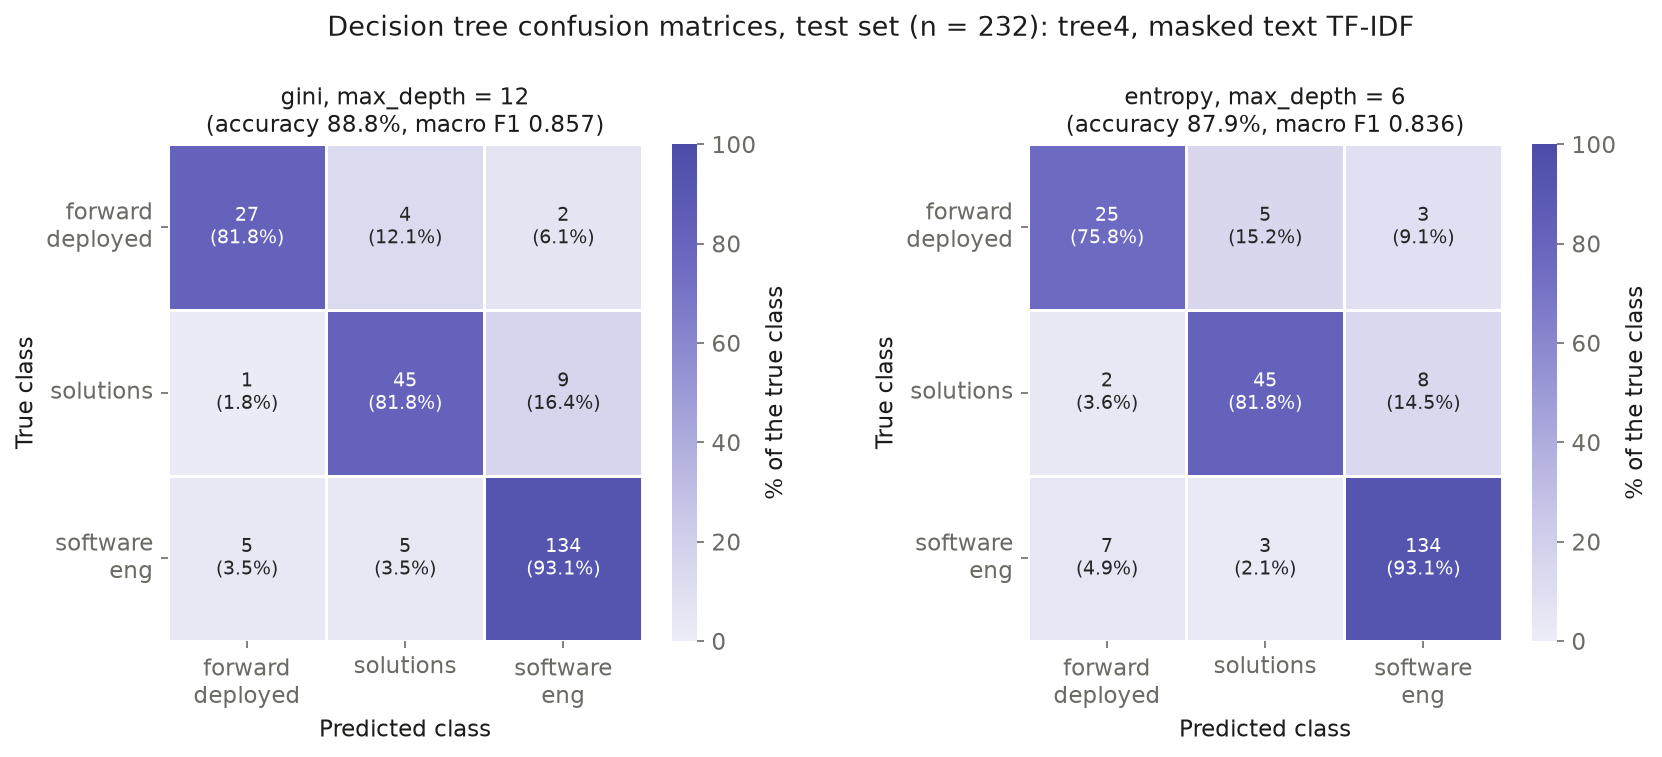

In [32]:
fig = dt.plot_confusion_dt(dt_results["tree4"], "tree4, " + dt.TREES["tree4"][0])
save(fig, "dt_confusion_tree4")

## Insight
Reading the job text, the Gini tree gets 88.8% right and finds 27 of 33 forward_deployed postings, the most of any model. Naive Bayes is still more accurate overall.

### Tree diagrams

tree1: fitted depth 35, drawn to depth 2; truncated: True


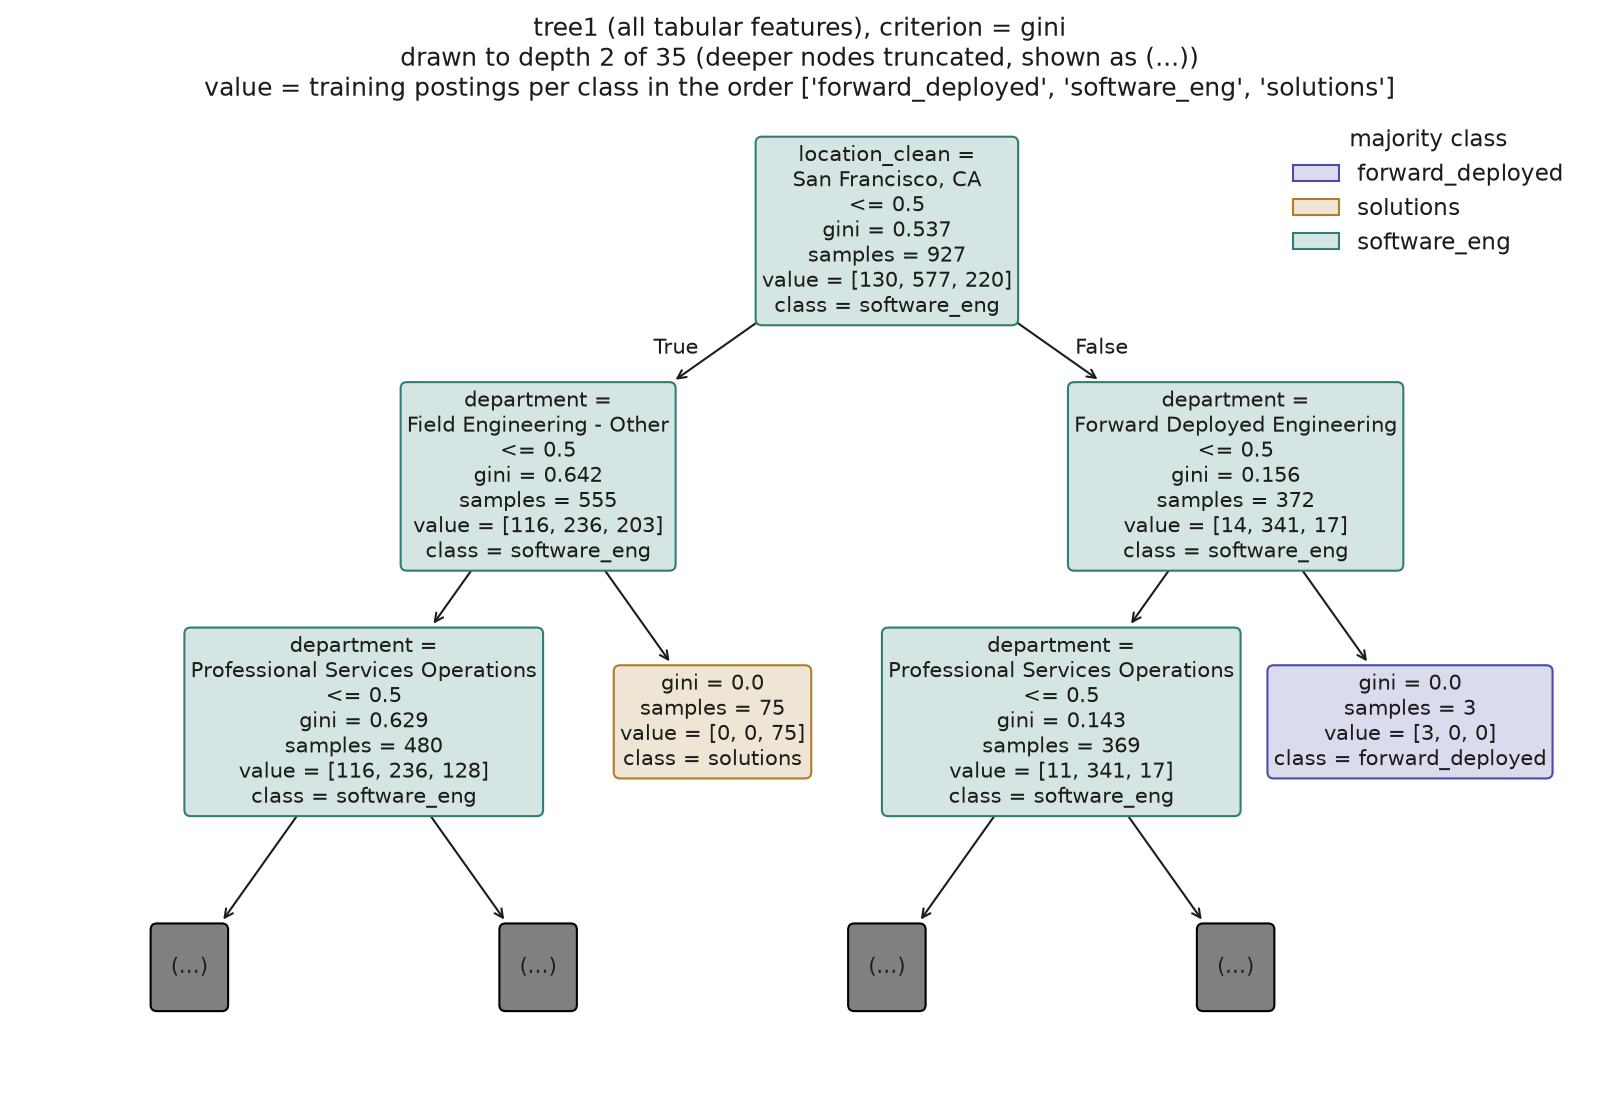

In [33]:
# the gini tree is drawn; the entropy tree's numbers are in the results above
fig, truncated = dt.plot_tree_diagram(dt_results["tree1"]["gini"]["model"],
                                      "tree1 (" + dt.TREES["tree1"][0] + "), criterion = gini")
save(fig, "dt_tree1_diagram")
fitted = dt_results["tree1"]["gini"]["model"].named_steps["tree"]
print(f"tree1: fitted depth {fitted.get_depth()}, drawn to depth {dt.PLOT_DEPTH}; truncated: {truncated}")

## Insight
The first question is whether the job is in San Francisco. After that, every question shown is about department, and one department question alone picks out 75 postings that are all solutions.

tree2: fitted depth 12, drawn to depth 2; truncated: True


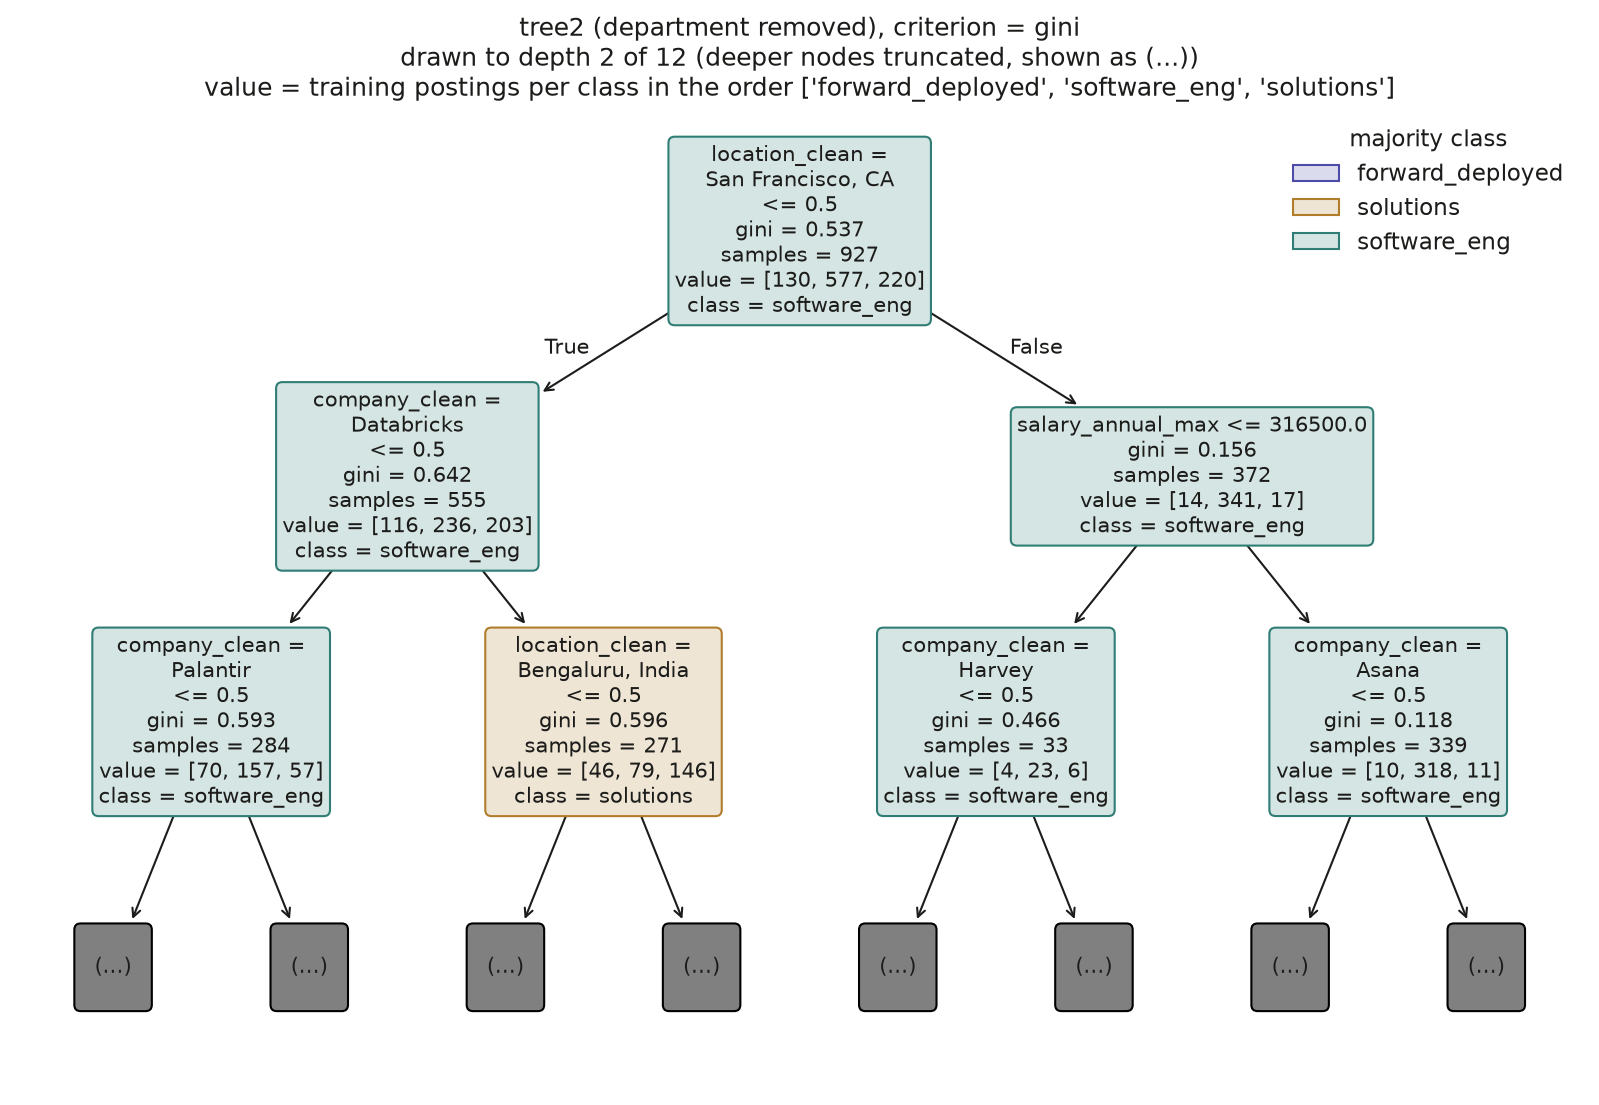

In [34]:
# the gini tree is drawn; the entropy tree's numbers are in the results above
fig, truncated = dt.plot_tree_diagram(dt_results["tree2"]["gini"]["model"],
                                      "tree2 (" + dt.TREES["tree2"][0] + "), criterion = gini")
save(fig, "dt_tree2_diagram")
fitted = dt_results["tree2"]["gini"]["model"].named_steps["tree"]
print(f"tree2: fitted depth {fitted.get_depth()}, drawn to depth {dt.PLOT_DEPTH}; truncated: {truncated}")

## Insight
Without department, the tree asks about the company instead: Databricks, Palantir, Harvey and Asana. Databricks jobs outside San Francisco are the only group shown where solutions is the largest class.

tree3: fitted depth 12, drawn to depth 2; truncated: True


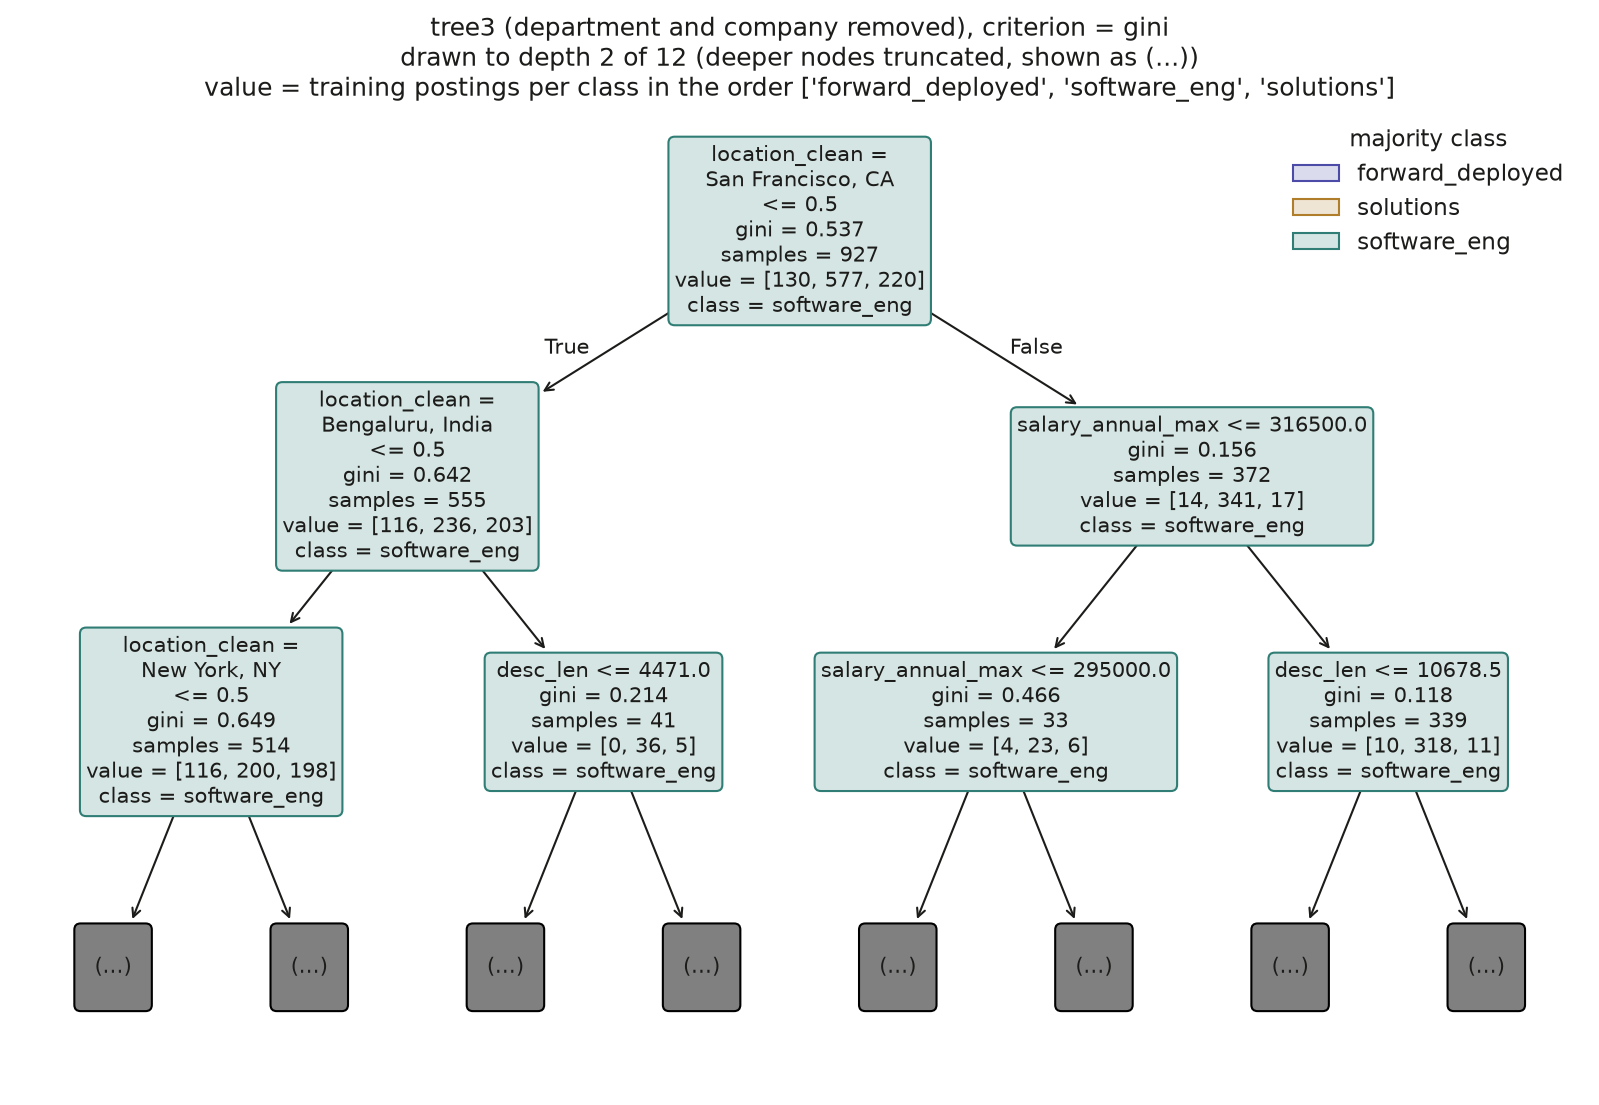

In [35]:
# the gini tree is drawn; the entropy tree's numbers are in the results above
fig, truncated = dt.plot_tree_diagram(dt_results["tree3"]["gini"]["model"],
                                      "tree3 (" + dt.TREES["tree3"][0] + "), criterion = gini")
save(fig, "dt_tree3_diagram")
fitted = dt_results["tree3"]["gini"]["model"].named_steps["tree"]
print(f"tree3: fitted depth {fitted.get_depth()}, drawn to depth {dt.PLOT_DEPTH}; truncated: {truncated}")

## Insight
Without department or company, the tree asks about location, salary and description length. Every group in the top two levels is still mostly software_eng.

tree4: fitted depth 12, drawn to depth 2; truncated: True


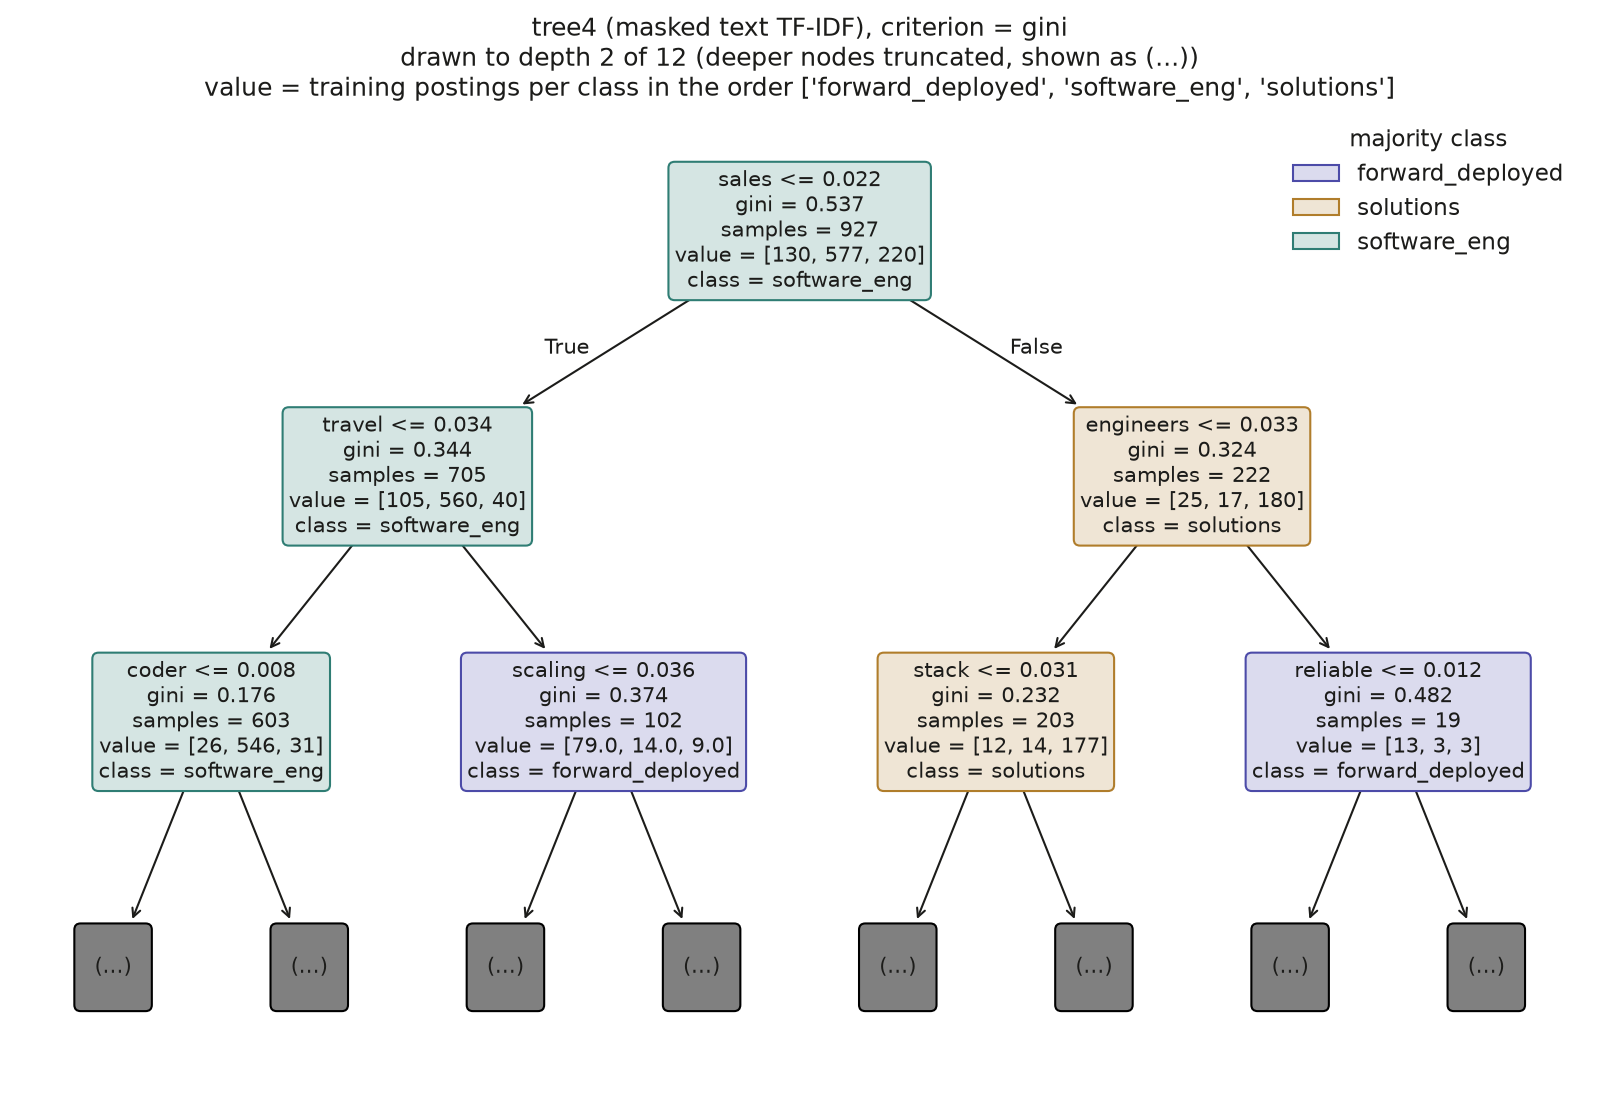

In [36]:
# the gini tree is drawn; the entropy tree's numbers are in the results above
fig, truncated = dt.plot_tree_diagram(dt_results["tree4"]["gini"]["model"],
                                      "tree4 (" + dt.TREES["tree4"][0] + "), criterion = gini")
save(fig, "dt_tree4_diagram")
fitted = dt_results["tree4"]["gini"]["model"].named_steps["tree"]
print(f"tree4: fitted depth {fitted.get_depth()}, drawn to depth {dt.PLOT_DEPTH}; truncated: {truncated}")

## Insight
The first question is how much a posting uses "sales", and those that use it a lot are mostly solutions. Postings that use "travel" a lot are mostly forward_deployed.

### Feature importance

,importance
department,0.5877
location_clean,0.2054
company_clean,0.0888
desc_len,0.0707
salary_annual_min,0.0318
workplaceType,0.0092
location_count,0.0044
is_multi_location,0.0020
salary missing (indicator),0.0000
salary_annual_max,0.0000


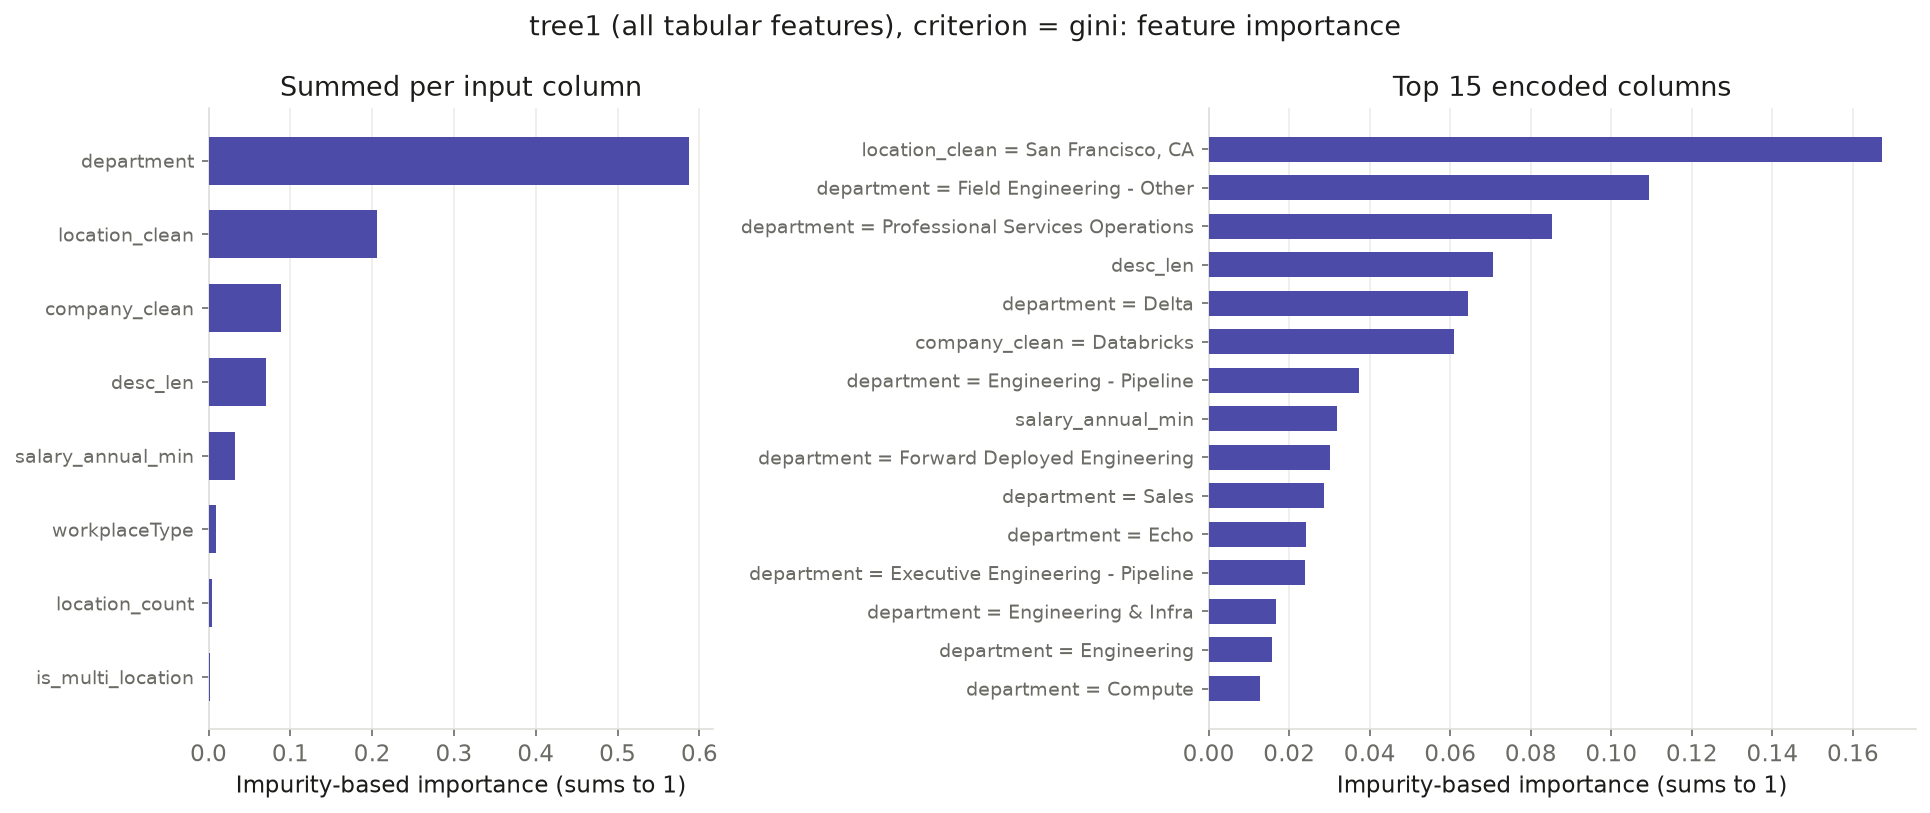

In [37]:
model = dt_results["tree1"]["gini"]["model"]
fig = dt.plot_importance(model, "tree1 (" + dt.TREES["tree1"][0] + "), criterion = gini: feature importance")
save(fig, "dt_tree1_importance")
imp, by_source = dt.importances(model)
display(by_source.round(4).to_frame("importance"))

## Insight
Department makes up 58.8% of what tree 1 relies on, about three times as much as location (20.5%). Salary barely matters (3.2%).

,importance
location_clean,0.4160
desc_len,0.2831
company_clean,0.1752
salary_annual_min,0.0460
salary_annual_max,0.0366
workplaceType,0.0334
salary missing (indicator),0.0065
location_count,0.0031
is_multi_location,0.0000


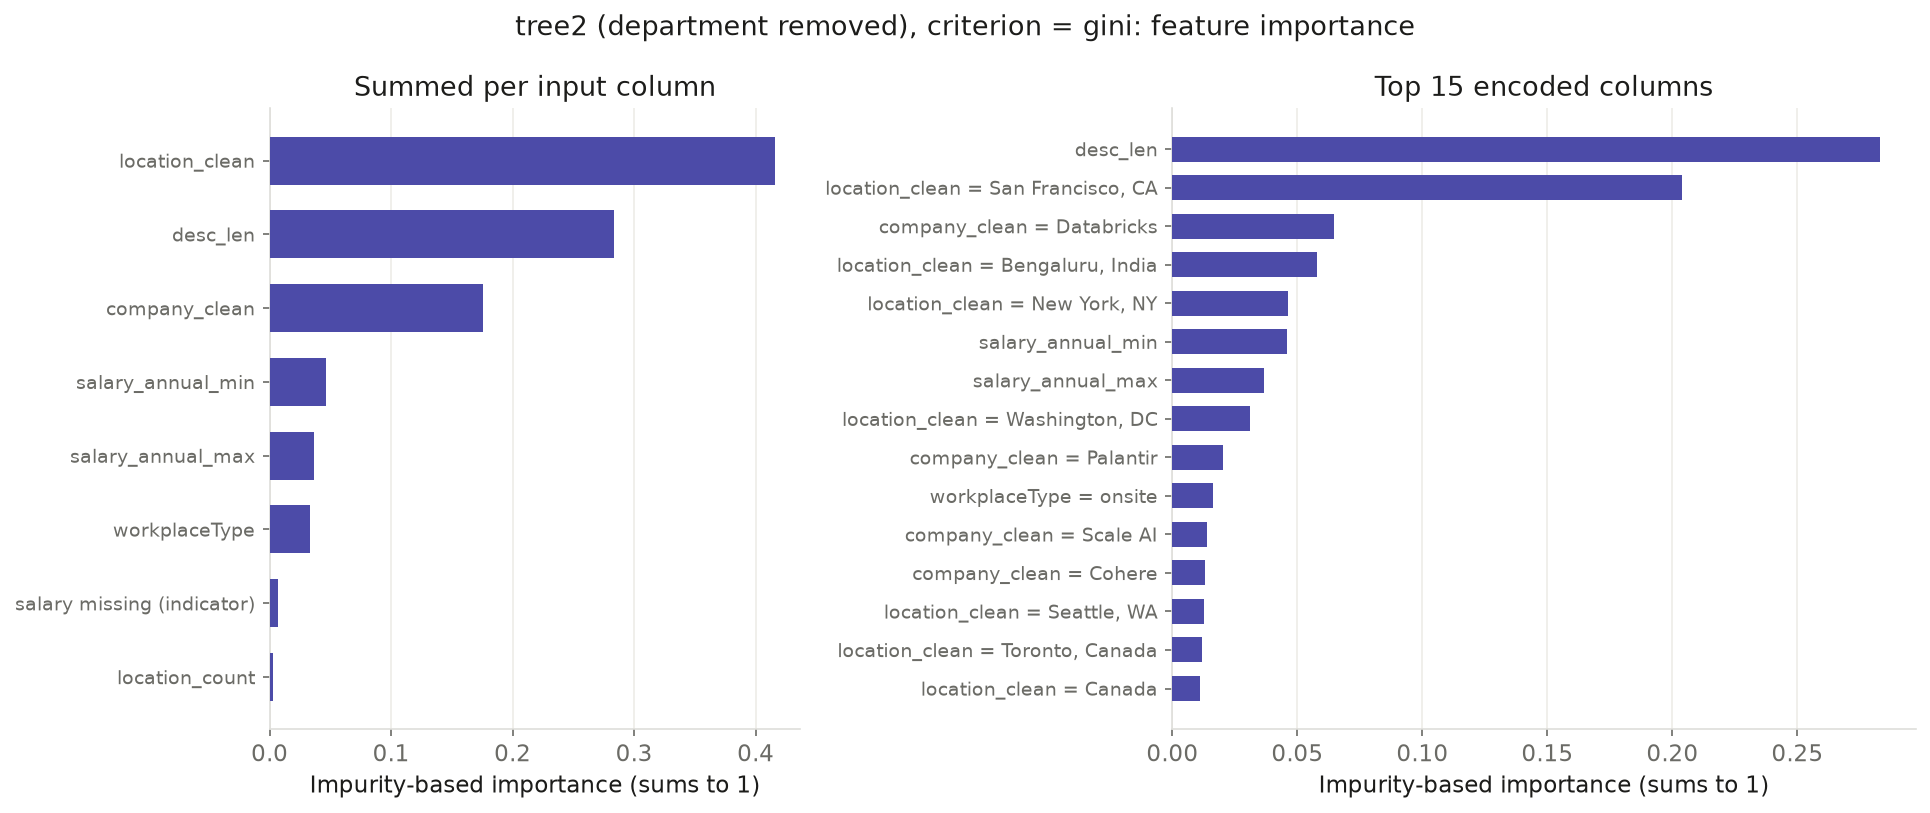

In [38]:
model = dt_results["tree2"]["gini"]["model"]
fig = dt.plot_importance(model, "tree2 (" + dt.TREES["tree2"][0] + "), criterion = gini: feature importance")
save(fig, "dt_tree2_importance")
imp, by_source = dt.importances(model)
display(by_source.round(4).to_frame("importance"))

## Insight
Without department, location (41.6%) and description length (28.3%) matter most, ahead of company (17.5%).

,importance
location_clean,0.4486
desc_len,0.3430
salary_annual_min,0.0909
workplaceType,0.0527
salary_annual_max,0.0476
is_multi_location,0.0081
salary missing (indicator),0.0050
location_count,0.0041


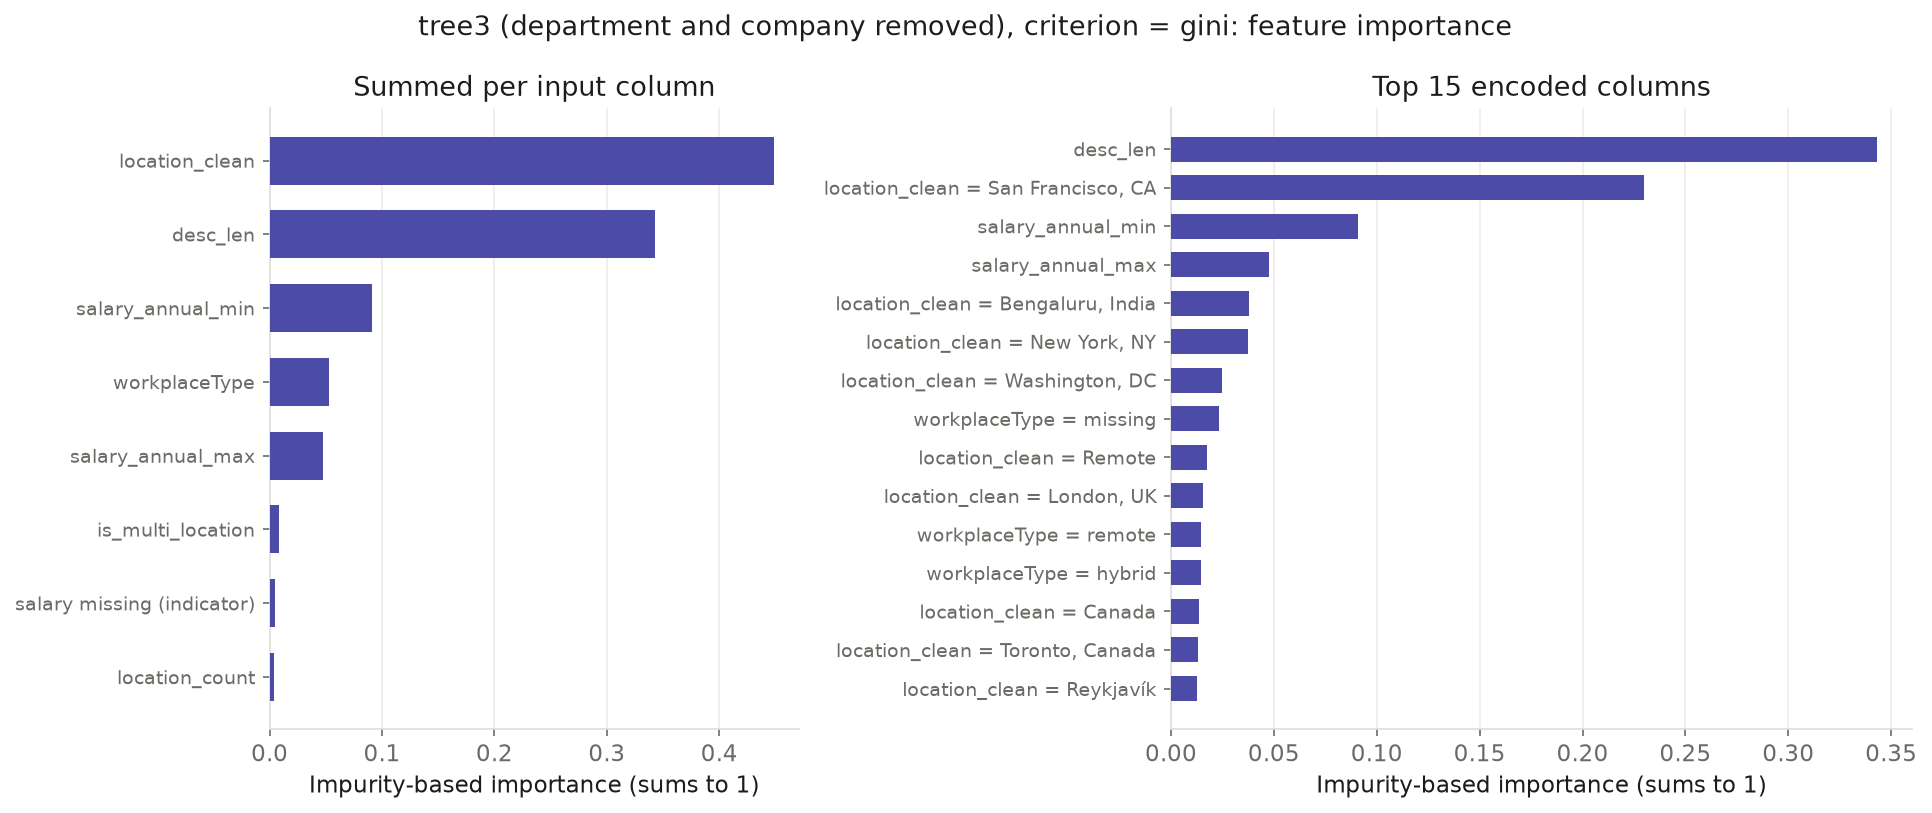

In [39]:
model = dt_results["tree3"]["gini"]["model"]
fig = dt.plot_importance(model, "tree3 (" + dt.TREES["tree3"][0] + "), criterion = gini: feature importance")
save(fig, "dt_tree3_importance")
imp, by_source = dt.importances(model)
display(by_source.round(4).to_frame("importance"))

## Insight
Location (44.9%) and description length (34.3%) make up almost four-fifths of what tree 3 relies on.

### Worked example: Gini, entropy and information gain

In [40]:
# tree 1 (gini): class counts at every node, from the training postings that reach it
wm = dt_results["tree1"]["gini"]["model"]
wtree = wm.named_steps["tree"]
node_counts = dt.node_class_counts(wm, X_tab.iloc[train], y.iloc[train])
node_counts["n"] = node_counts.sum(axis=1)
node_counts["depth"] = dt.node_depths(wtree)
node_counts["split"] = [f"{dt.feature_names(wm)[f]} <= {th:.4g}" if f >= 0 else "leaf"
                        for f, th in zip(wtree.tree_.feature, wtree.tree_.threshold)]
assert (node_counts["n"] == wtree.tree_.n_node_samples).all()
print(f"{len(node_counts)} nodes; the first three levels:")
display(node_counts[node_counts.depth <= 2])

235 nodes; the first three levels:


,forward_deployed,solutions,software_eng,n,depth,split
0,130,220,577,927,0,"location_clean = San Francisco, CA <= 0.5"
1,116,203,236,555,1,department = Field Engineering - Other <= 0.5
2,116,128,236,480,2,department = Professional Services Operations <= 0.5
153,0,75,0,75,2,leaf
154,14,17,341,372,1,department = Forward Deployed Engineering <= 0.5
155,11,17,341,369,2,department = Professional Services Operations <= 0.5
234,3,0,0,3,2,leaf


In [41]:
# root split
root_lines = dt.split_arithmetic(wm, node_counts, 0)
print("\n".join(root_lines))

node 0 (depth 0): split on 'location_clean = San Francisco, CA' <= 0.5
  (one-hot feature: left = postings without this value, right = postings with it)
  class counts in the order ['forward_deployed', 'solutions', 'software_eng']:
    parent (node 0): [130, 220, 577]  n = 927
    left   (node 1): [116, 203, 236]  n = 555
    right  (node 154): [14, 17, 341]  n = 372
  GINI
    parent: 1 - [(130/927)^2 + (220/927)^2 + (577/927)^2] = 1 - 0.4634 = 0.5366
    left  : 1 - [(116/555)^2 + (203/555)^2 + (236/555)^2] = 1 - 0.3583 = 0.6417
    right : 1 - [(14/372)^2 + (17/372)^2 + (341/372)^2] = 1 - 0.8438 = 0.1562
    after the split (weighted): (555/927) x 0.6417 + (372/927) x 0.1562 = 0.4469
    decrease = 0.5366 - 0.4469 = 0.0897
  ENTROPY (bits)
    parent: -[(130/927)log2(130/927) + (220/927)log2(220/927) + (577/927)log2(577/927)] = 1.3157
    left  : -[(116/555)log2(116/555) + (203/555)log2(203/555) + (236/555)log2(236/555)] = 1.5273
    right : -[(14/372)log2(14/372) + (17/372)log2(17/

In [42]:
# one internal split lower down: the depth-2 internal node with the most training postings
depth2 = node_counts[(node_counts.depth == 2) & (node_counts.split != "leaf")]
INTERNAL_NODE = int(depth2.n.idxmax())
internal_lines = dt.split_arithmetic(wm, node_counts, INTERNAL_NODE)
print("\n".join(internal_lines))

node 2 (depth 2): split on 'department = Professional Services Operations' <= 0.5
  (one-hot feature: left = postings without this value, right = postings with it)
  class counts in the order ['forward_deployed', 'solutions', 'software_eng']:
    parent (node 2): [116, 128, 236]  n = 480
    left   (node 3): [73, 125, 236]  n = 434
    right  (node 140): [43, 3, 0]  n = 46
  GINI
    parent: 1 - [(116/480)^2 + (128/480)^2 + (236/480)^2] = 1 - 0.3712 = 0.6288
    left  : 1 - [(73/434)^2 + (125/434)^2 + (236/434)^2] = 1 - 0.4069 = 0.5931
    right : 1 - [(43/46)^2 + (3/46)^2 + (0/46)^2] = 1 - 0.8781 = 0.1219
    after the split (weighted): (434/480) x 0.5931 + (46/480) x 0.1219 = 0.5479
    decrease = 0.6288 - 0.5479 = 0.0808
  ENTROPY (bits)
    parent: -[(116/480)log2(116/480) + (128/480)log2(128/480) + (236/480)log2(236/480)] = 1.5072
    left  : -[(73/434)log2(73/434) + (125/434)log2(125/434) + (236/434)log2(236/434)] = 1.4277
    right : -[(43/46)log2(43/46) + (3/46)log2(3/46) + 0] 

## Insight
At the root, the San Francisco split lowers Gini from 0.537 to 0.447 and gives an information gain of 0.202 bits. The San Francisco group is 92% software_eng.

### Diagnostics

In [43]:
# department x class, and the share of postings in a department that is >= 90% one class
dept_ct = pd.crosstab(df.department, y).reindex(columns=nb.CLASSES)
dept_ct["n"] = dept_ct.sum(axis=1)
dept_ct["top class share"] = dept_ct[nb.CLASSES].max(axis=1) / dept_ct.n
dept_ct = dept_ct.sort_values("n", ascending=False)
in_pure = df.department.map(dept_ct["top class share"])
dept_lines = [f"departments: {len(dept_ct)}",
              f"postings in a department that is >= 90% one class: {(in_pure >= 0.9).sum()} of {len(df)} "
              f"({(in_pure >= 0.9).mean():.1%})",
              f"postings in a department that is 100% one class: {(in_pure == 1).sum()}"]
print("\n".join(dept_lines))
display(dept_ct.round(3))

departments: 122
postings in a department that is >= 90% one class: 1023 of 1159 (88.3%)
postings in a department that is 100% one class: 535


role_family,forward_deployed,solutions,software_eng,n,top class share
department,,,,,
Engineering,3,1,137,141,0.972
Engineering - Pipeline,0,2,95,97,0.979
Field Engineering - Other,0,89,0,89,1.000
Applied AI,3,2,60,65,0.923
Professional Services Operations,58,4,0,62,0.935
...,...,...,...,...,...
Product Management,0,0,1,1,1.000
Engineering : AI Foundation,0,0,1,1,1.000
Early Career,0,0,1,1,1.000


In [44]:
company_ct = pd.crosstab(df.company_clean, y).reindex(columns=nb.CLASSES)
company_ct["n"] = company_ct.sum(axis=1)
company_ct = company_ct.sort_values("n", ascending=False)
company_ct

role_family,forward_deployed,solutions,software_eng,n
company_clean,,,,
Databricks,61,176,148,385
OpenAI,17,19,165,201
Anthropic,3,8,101,112
Palantir,42,13,37,92
Scale AI,15,6,41,62
Cohere,18,11,15,44
Harvey,0,4,37,41
Sierra,0,1,37,38
Vercel,2,7,18,27


In [45]:
# how far tree 1's test-set decisions rest on department
dept_decisions = pd.DataFrame({c: dt.department_decisions(r["model"], X_tab.iloc[test])
                               for c, r in dt_results["tree1"].items()})
dept_decisions

,gini,entropy
only department splits on the path,0.000000,0.000000
at least one department split on the path,1.000000,1.000000
final split before the leaf is department,0.534483,0.612069
mean share of path splits on department,0.694189,0.608687
test postings,232.000000,232.000000


## Insight
88.3% of postings sit in a department that is at least 90% one role. Every one of tree 1's test predictions uses a department question.

### Check: where department comes from

In [46]:
# department is not computed anywhere in the pipeline: clean_ats.py carries the scraped
# column through FINAL_COLUMNS, and clean_ats_stage2.py only reads it (has_department).
# Compare every posting's department with the raw scraped value for the same jobId,
# loading the raw files the way clean_ats.py does (freshest scrape per jobId).
from src import clean_ats
raw_ats, _ = clean_ats.load_all()
raw_ats = raw_ats.sort_values("scrapedAt").drop_duplicates("jobId", keep="last").set_index("jobId")
raw_dept = df.jobId.map(raw_ats["department"])
role_phrase_dept = df.department.str.contains(r"forward deploy|solution|field eng|software eng|deployment",
                                              case=False, regex=True)
provenance_lines = [
    f"postings with a raw row for their jobId: {df.jobId.isin(raw_ats.index).sum()} of {len(df)}",
    f"department identical to the raw scraped value: {(df.department.fillna('') == raw_dept.fillna('')).sum()} of {len(df)}",
    f"department equal to the title: {(df.department == df.title).sum()}",
    f"department text containing the full title: {sum(str(t).lower() in str(d).lower() for d, t in zip(df.department, df.title))}",
    f"department name containing a role phrase (employer-assigned): {role_phrase_dept.sum()} "
    f"{y[role_phrase_dept].value_counts().reindex(nb.CLASSES, fill_value=0).to_dict()}"]
print("\n".join(provenance_lines))
pd.crosstab(df.department[role_phrase_dept], y[role_phrase_dept]).reindex(columns=nb.CLASSES, fill_value=0)

postings with a raw row for their jobId: 1159 of 1159
department identical to the raw scraped value: 1159 of 1159
department equal to the title: 0
department text containing the full title: 9
department name containing a role phrase (employer-assigned): 221 {'forward_deployed': 18, 'solutions': 171, 'software_eng': 32}


role_family,forward_deployed,solutions,software_eng
department,,,
Field Engineering - Indirect,1,1,0
Delivery Solutions Architects,0,24,0
Field Engineering,1,12,0
Field Engineering - BIF,1,0,0
Field Engineering - Enablement,0,1,0
Field Engineering - FE Direct Emerging,0,6,0
Field Engineering - FE Direct Enterprise,0,10,0
Field Engineering - FE Direct Regulated,0,23,0
Field Engineering - FE Invested DSA,0,1,0


## Insight
Department comes straight from the job board, not from the title. But 13 department names already contain a role name, such as "Field Engineering", covering 221 postings.

### Check: can the employer be recovered from tree 3's features?

In [47]:
# predict company_clean from tree 3's exact feature set (same encoder, split and CV procedure)
company = df.company_clean
company_probe = dt.identity_probe(X_tab, company, train, test, "tree3")
print("\n".join(dt.probe_lines("tree 3 features -> company_clean", company_probe)))
display(company_probe["per_label"].round(3))

tree 3 features -> company_clean
  labels in training rows: 19 (smallest has 2 rows); test rows whose label never occurs in training: 0
  CV accuracy by max_depth: 1: 0.4897, 2: 0.5782, 3: 0.6117, 4: 0.6645, 5: 0.7012, 6: 0.7174, 8: 0.7379, 10: 0.7486, 12: 0.7422, 15: 0.7443, 20: 0.7454, none: 0.7476
  selected max_depth: 10; train accuracy 0.9061; TEST ACCURACY 0.7155; majority baseline (Databricks) 0.3233
  importance summed per input column: desc_len 0.2741, location_clean 0.1739, salary missing (indicator) 0.1653, workplaceType 0.1528, salary_annual_min 0.1116, salary_annual_max 0.0748, location_count 0.0298, is_multi_location 0.0176


,n_test,recall
label,,
Databricks,75,0.827
OpenAI,45,0.867
Anthropic,14,0.929
Palantir,14,1.000
Scale AI,11,0.273
Harvey,9,0.333
Ramp,9,0.778
Cohere,8,0.375
Stripe,7,0.429


In [48]:
# description length per company (all 1,159 postings)
desc_by_company = df.groupby("company_clean").desc_len.describe()[["count", "25%", "50%", "75%"]]
desc_by_company["IQR"] = desc_by_company["75%"] - desc_by_company["25%"]
desc_by_company = desc_by_company.rename(columns={"50%": "median"}).sort_values("count", ascending=False)
desc_by_company[["count", "median", "25%", "75%", "IQR"]].astype(int)

,count,median,25%,75%,IQR
company_clean,,,,,
Databricks,385,5194,4502,5937,1435
OpenAI,201,6206,5514,7228,1714
Anthropic,112,7664,7121,8674,1552
Palantir,92,7443,6308,8340,2031
Scale AI,62,6255,5530,7322,1791
Cohere,44,6105,5445,6977,1531
Harvey,41,5420,4402,5814,1412
Sierra,38,7609,6645,7760,1115
Vercel,27,4813,4180,6853,2673


In [49]:
# location_clean x company_clean (all 1,159 postings), and for the 10 most common locations
# the share of postings from the single largest company
loc_company = pd.crosstab(df.location_clean.fillna("missing"), company)
loc_company = loc_company.loc[loc_company.sum(axis=1).sort_values(ascending=False).index]
loc_company_share = dt.largest_share(df.location_clean.fillna("missing"), company)
display(loc_company_share.round(3))
loc_company

,postings,largest,largest n,share
location_clean,,,,
"San Francisco, CA",470,OpenAI,163,0.347
"New York, NY",93,Palantir,26,0.280
"London, UK",88,Databricks,22,0.250
"Washington, DC",58,Palantir,24,0.414
Remote,55,Databricks,21,0.382
"Bengaluru, India",54,Databricks,49,0.907
Singapore,22,Databricks,14,0.636
United States,22,Databricks,17,0.773
"Tokyo, Japan",20,Databricks,13,0.650


company_clean,Airtable,Amplitude,Anthropic,Asana,Cohere,Databricks,Discord,Figma,Harvey,Linear,OpenAI,Palantir,Perplexity,Ramp,Scale AI,Sierra,Stripe,Vercel,Webflow
location_clean,,,,,,,,,,,,,,,,,,,
"San Francisco, CA",4,10,84,1,3,51,21,12,25,0,163,2,22,1,24,27,1,19,0
"New York, NY",2,0,3,6,1,11,0,0,7,0,5,26,0,20,11,0,0,1,0
"London, UK",0,0,11,2,3,22,0,2,1,1,5,13,0,1,14,8,0,4,1
"Washington, DC",0,0,0,0,1,23,0,0,0,0,5,24,0,0,5,0,0,0,0
Remote,2,1,9,0,0,21,1,0,0,0,6,0,0,4,0,0,0,3,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Dubai,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"Riyadh, Saudi Arabia",0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
Costa Rica,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


In [50]:
# tree 2 keeps company_clean, so predicting company from it is trivial; the parallel test
# is whether tree 2's features recover the column it drops, department
dept_probe = dt.identity_probe(X_tab, df.department, train, test, "tree2")
print("\n".join(dt.probe_lines("tree 2 features -> department", dept_probe)))
display(dept_probe["per_label"].head(20).round(3))
loc_dept_share = dt.largest_share(df.location_clean.fillna("missing"), df.department)
loc_dept_share.round(3)

tree 2 features -> department
  labels in training rows: 107 (smallest has 1 rows); test rows whose label never occurs in training: 16
  CV accuracy by max_depth: 1: 0.1791, 2: 0.2610, 3: 0.3020, 4: 0.3495, 5: 0.3927, 6: 0.4197, 8: 0.4790, 10: 0.4822, 12: 0.4854, 15: 0.4800, 20: 0.4941, none: 0.4876
  selected max_depth: 20; train accuracy 0.9773; TEST ACCURACY 0.4440; majority baseline (Engineering) 0.1552
  importance summed per input column: desc_len 0.4200, company_clean 0.1928, location_clean 0.1892, workplaceType 0.0611, salary_annual_max 0.0500, salary_annual_min 0.0426, location_count 0.0339, is_multi_location 0.0089, salary missing (indicator) 0.0016


,n_test,recall
label,,
Engineering,36,0.667
Engineering - Pipeline,20,0.750
Scaling,15,0.333
Field Engineering - Other,14,0.643
Professional Services Operations,14,0.357
Applied AI,10,0.500
Software Engineering - Infrastructure,7,0.143
Dev,6,0.333
Finance,6,0.167


,postings,largest,largest n,share
location_clean,,,,
"San Francisco, CA",470,Engineering,77,0.164
"New York, NY",93,Engineering,27,0.290
"London, UK",88,Field Engineering - Other,15,0.170
"Washington, DC",58,Delta,10,0.172
Remote,55,Professional Services Operations,8,0.145
"Bengaluru, India",54,Engineering - Pipeline,34,0.630
Singapore,22,Field Engineering - Other,9,0.409
United States,22,Delivery Solutions Architects,5,0.227
"Tokyo, Japan",20,Field Engineering - Other,7,0.350


## Insight
Location and description length can still name the employer 71.6% of the time, against 32.3% by guessing. Leaving a column out does not remove what it tells.

### Check: gini against entropy at the same depth

In [51]:
# both criteria refitted at the gini-selected max_depth of each tree (secondary table;
# the tuned table above stays the main one)
fixed_depth = dt.fixed_depth_comparison(X_by_tree, y, train, test, dt_results)
fixed_depth

max_depth (gini-selected) fitted depth train accuracy  \
tree  criterion                                                         
tree1 gini                           none           35            1.0   
      entropy                        none           27            1.0   
tree2 gini                             12           12        0.93959   
      entropy                          12           12       0.934196   
tree3 gini                             12           12       0.899676   
      entropy                          12           12       0.886731   
tree4 gini                             12           12       0.990291   
      entropy                          12           10            1.0   

                test accuracy  macro F1  
tree  criterion                          
tree1 gini           0.922414  0.895533  
      entropy        0.900862  0.876126  
tree2 gini           0.767241  0.648304  
      entropy         0.75431  0.633159  
tree3 gini            0.75431  0.624168  
      entropy        0.711207  0.617764  
tree4 gini           0.887931  0.857069  
      entropy        0.887931  0.850364

## Insight
At the same depth, Gini is as good as or better than entropy for all four trees. The difference is small next to the effect of the features.

### Outputs

In [52]:
dt_report += ["", "DEPTH SELECTION (CV accuracy, mean over folds)",
              *[f"  {line}" for line in cv_curves.round(4).unstack("max_depth")["cv_mean"]
                [[dt.depth_label(d) for d in dt.DEPTHS]].to_string().splitlines()],
              "", "SUMMARY (test set, n = %d)" % len(test),
              f"  majority-class baseline ({baseline[0]}): {baseline[1]:.4f}",
              *[f"  {line}" for line in dt_summary.round(4).to_string().splitlines()],
              "", "TREE 4 VERSUS MASKED NAIVE BAYES (same masked-text TF-IDF features)",
              *[f"  {line}" for line in nb_vs_dt]]
for t in dt_results:
    for c, r in dt_results[t].items():
        dt_report += ["", *dt.result_lines(t, r, baseline)]
for t in ["tree1", "tree2", "tree3"]:
    imp, by_source = dt.importances(dt_results[t]["gini"]["model"])
    dt_report += ["", f"FEATURE IMPORTANCE, {t} (gini), summed per input column:",
                  *[f"  {k}: {v:.4f}" for k, v in by_source.items()],
                  "  top 15 encoded columns:", *[f"  {k}: {v:.4f}" for k, v in imp.head(15).items()]]
dt_report += ["", "WORKED EXAMPLE, tree 1 (gini): root split", *[f"  {line}" for line in root_lines],
              "", f"WORKED EXAMPLE, tree 1 (gini): internal split (node {INTERNAL_NODE}, the depth-2 "
              "internal node with the most training postings)", *[f"  {line}" for line in internal_lines],
              "", "DIAGNOSTIC: department x class (all 1,159 postings)", *[f"  {line}" for line in dept_lines],
              *[f"  {line}" for line in dept_ct.round(3).to_string().splitlines()],
              "", "DIAGNOSTIC: company_clean x class (all 1,159 postings)",
              *[f"  {line}" for line in company_ct.to_string().splitlines()],
              "", "DIAGNOSTIC: tree 1 test-set decisions and department (share of the 232 test postings)",
              *[f"  {line}" for line in dept_decisions.round(4).to_string().splitlines()]]

def indent(frame):
    return [f"  {line}" for line in frame.to_string().splitlines()]

dt_report += ["", "CHECK: DEPARTMENT PROVENANCE (scraped ATS field; not derived in the pipeline)",
              *[f"  {line}" for line in provenance_lines],
              "", "CHECK: EMPLOYER IDENTIFIABLE FROM TREE 3 FEATURES", *dt.probe_lines("tree 3 features -> company_clean", company_probe),
              "  per company (test rows, recall):", *indent(company_probe["per_label"].round(3)),
              "  desc_len per company (all postings):", *indent(desc_by_company[["count", "median", "25%", "75%", "IQR"]].astype(int)),
              "  10 most common locations, share from the largest company:", *indent(loc_company_share.round(3)),
              "  location_clean x company_clean (all postings):", *indent(loc_company),
              "", "CHECK: DEPARTMENT IDENTIFIABLE FROM TREE 2 FEATURES", *dt.probe_lines("tree 2 features -> department", dept_probe),
              "  per department, 20 largest in the test rows (recall):", *indent(dept_probe["per_label"].head(20).round(3)),
              "  10 most common locations, share from the largest department:", *indent(loc_dept_share.round(3)),
              "", "CHECK: GINI AGAINST ENTROPY AT THE GINI-SELECTED DEPTH (secondary; the tuned table is the main one)",
              *indent(fixed_depth.round(4))]
dt.REPORT_PATH.write_text("\n".join(dt_report) + "\n")
print(f"wrote {dt.REPORT_PATH.relative_to(tc.ROOT)} ({len(dt_report)} lines)")

wrote results/dt_report.txt (842 lines)
